## Important Note

Due to the current policy of SLURM schedulers to charge the full allocated time to the account fairshare (regardless of timeout), it is a good idea to refurbish the slurm scheduler to adopt a "take and hold" approach to O2 resources since you get penalized for time that you request but do not use making allocation of resources later in the day (after running one or two steps) more difficult.

The primary piece of code that would need to be written for a take and hold model would need to include the following:

- More sophisticated memory clearing of the dask_controller object (total memory clearing without a restart that leads to crashes) THIS FIRST 
- Rule-based adjustments of chunk sizes to limit per-node memory use to make sure a flat memory request can be made at cluster initialization

# Introduction

This notebook contains the entire `TrenchRipper` pipline, divided into simple steps. This pipline is ideal for Mother <br>Machine image data where cells possess fluorescent segmentation markers. Segmentation on phase or brightfield data <br>is being developed, but is still an experimental feature.

The steps in this pipeline are as follows:
1. Extracting your Mother Machine data (.nd2) into hdf5 format
2. Identifying and cropping individual trenches into kymographs
3. Segmenting cells with a fluorescent marker
4. Determining lineages and object properties

In each step, the user will dynamically specify parameters using a series of interactive diagnostics on their dataset. <br>Following this, a parameter file will be written to disk and then used to deploy a parallel computation on the <br>dataset, either locally or on a SLURM cluster.


This is intended as an end-to-end solution to analyzing Mother Machine data. As such, **it is not trivial to plug data <br>directly into intermediate steps**, as it will lack the correct formatting and associated metadata. A notable <br>exception to this is using another program to segment data. The library references binary segmentation masks using <br>only metadata derived from their associated kymographs. As such, it is possible to generate segmentations on these <br>kymographs elsewhere and place them into the segmentation data path to have `TrenchRipper` act on those <br>segmentations instead. More on this in the segmentation section...

#### Imports

Run this section to import all relavent packages and libraries used in this notebook. You must run this everytime you open a new python kernel.

In [4]:
# import paulssonlab.deaton.trenchripper.trenchripper as tr
import trenchripper as tr

import warnings

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [5]:
# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

# Part 0: Flat Field Generation

### Dark Image

flatfieldpath = "/home/cas77/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/DarkImage_40x_Phase.nd2"
outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/40x_DarkImage.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### Cy5-Penta

flatfieldpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy5-Penta_20x_Phase.nd2"
outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy5-Penta_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### Cy7-Penta

flatfieldpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy7-Penta_20x_Phase.nd2"
outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy7-Penta_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### GFP-Penta

flatfieldpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Phase.nd2"
outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### MCherry

flatfieldpath = "/home/cas77/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_20x/mCherry_20x_Phase.nd2"
outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_20x/mCherry_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

In [ ]:
tr.generate_flatfield('/home/lag36/scratch/lag36/2024-10-27_Flat_Fields_Iris_9_20x/20X_Dark.nd2',
                      '/home/lag36/scratch/lag36/2024-10-27_Flat_Fields_Iris_9_20x/20X_Dark.tiff')

# tr.generate_flatfield('/home/lag36/scratch/lag36/2024-10-27_Flat_Fields_Iris_9_20x/mCherry_20x_Phase.nd2',
#                       '/home/lag36/scratch/lag36/2024-10-27_Flat_Fields_Iris_9_20x/mCherry_20x_Phase.tiff')

/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff
/home/lag36/scratch/lag36/2024-10-27_Flat_Fields_Iris_9_20x/mCherry_20x_Phase.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_mCherry.tiff


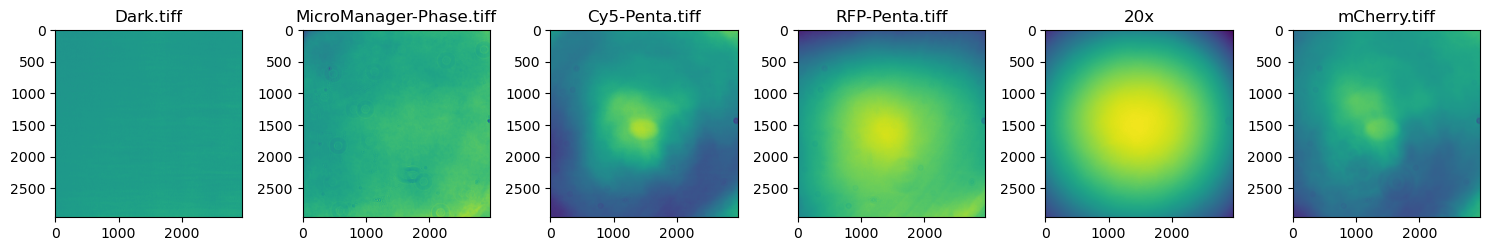

In [35]:
import tifffile
from matplotlib import pyplot as plt

dark_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff"
)

Cy5_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff"
)

RFP_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff"
)

Mcherry_outputpath = (
    "/home/lag36/scratch/lag36/2024-10-27_Flat_Fields_Iris_9_20x/mCherry_20x_Phase.tiff"
)

BF_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff"
)

Mcherry_old_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_mCherry.tiff"
)

fflist = [
    dark_outputpath,
    BF_outputpath,
    Cy5_outputpath,
    # Cy7_outputpath,
    # GFP_outputpath,
    RFP_outputpath,
    Mcherry_outputpath,
    Mcherry_old_outputpath
]

fig, axs = plt.subplots(figsize=(15, 20), nrows=1, ncols=len(fflist))

for i in range(len(fflist)):
    print(fflist[i])
    axs[i].imshow(tifffile.imread(fflist[i]))
    axs[i].set_title(fflist[i].split('/')[-1].split('_')[1]) #
    # axs[i].set_title(fflist[i].split("/")[-1].split("_")[1])  # CHANGED BY LUIS
plt.tight_layout()


# Part 1: Growth/Division

#### Specify Paths

Begin by defining the directory in which all processing will be done, as well as the initial nd2 file we will be <br>processing. This line should be run everytime you open a new python kernel.

The format should be: `headpath = "/path/to/folder"` and `nd2file = "/path/to/file.nd2"`

For example:
```
headpath = "/n/scratch2/de64/2019-05-31_validation_data"
nd2file = "/n/scratch2/de64/2019-05-31_validation_data/Main_Experiment.nd2"
```

Ideally, these files should be placed in a storage location with relatively fast I/O

In [6]:
headpath = "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/"
nd2file = "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Experiment.nd2"

## Extract to hdf5 files

In this section, we will be extracting our image data. Currently this notebook only supports `.nd2` format; however <br>there are `.tiff` extractors in the TrenchRipper source files that are being added to `Master.ipynb` soon.

In the abstract, this step will take a single `.nd2` file and split it into a set of `.hdf5` files stored in <br>`headpath/hdf5`. Splitting the file up in this way will facilitate quick procesing in later steps. Each field of <br>view will be split into one or more `.hdf5` files, depending on the number of images per file requested (more on <br>this later). 

To keep track of which output files correspond to which FOVs, as well as to keep track of experiment metadata, the <br>extractor also outputs a `metadata.hdf5` file in the `headpath` folder. The data from this step is accessible in <br>that `metadata.hdf5` file under the `global` key. If you would like to look at this metadata, you may use the <br>`tr.utils.pandas_hdf5_handler` to read from this file. Later steps will add additional metadata under different <br>keys into the `metadata.hdf5` file.

#### Start Dask Workers

First, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [4]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="1:00:00",
#     local=False,
#     n_workers=100,
#     n_workers_min=20,
#     memory="8GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

In [4]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="1:00:00",
#     local=False,
#     n_workers=500,
#     n_workers_min=20,
#     memory="3GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=400,
    n_workers_min=20,
    memory="6GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

50m
1:00:00


In [5]:
dask_controller.displaydashboard()

NameError: name 'dask_controller' is not defined

After running the above line, you will have a running Dask client. Run the line below and click the link to supervise <br>the computation being administered by the scheduler. 

Don't be alarmed if the screen starts mostly blank, it may take time for your workers to spin up. If you get a 404 <br>error on a cluster, it is likely that your ports are not being forwarded properly. If this occurs, please register <br>the issue on github.

##### Perform Extraction

Now that we have our cluster scheduler spun up, it is time to convert files. This will be handled by the <br>`hdf5_extractor` object. This extractor will pull up each FOV and split it such that each derived `.hdf5` file <br>contains, at maximum, N timepoints of that FOV per file. The image data stored in these files takes the <br>form of `(N,Y,X)` arrays that are accessible using the desired channel name as a key. 

The arguments for this extractor are:

 - **nd2file** : The filepath to the `.nd2` file you intend to extract.
 
 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **tpts_per_file** : The maximum number of timepoints stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **ignore_fovmetadata** : Used when `.nd2` data is corrupted and does not possess records for stage positions or <br>timepoints. Only set `False` if the extractor throws errors on metadata handling.

 - **nd2reader_override** : Overrides values in metadata recovered using the `nd2reader`. Currently set to <br>`{"z_levels":[],"z_coordinates":[]}` by default to correct a known issue where z coordinates are mistakenly <br>interpreted as a z stack. See the [nd2reader](https://rbnvrw.github.io/nd2reader/) documentation for more info.

In [6]:
hdf5_extractor = tr.ndextract.hdf5_fov_extractor(
    nd2file,
    headpath,
    tpts_per_file=67,#50,
    ignore_fovmetadata=False,
    nd2reader_override={"z_levels": [], "z_coordinates": []},
)

##### Extraction Parameters

Here, you may set the time interval you want to extract. Useful for cropping data to the period exhibiting the dynamics of interest.

Optionally take notes to add to the `metadata.hdf5` file. Notes may also be taken directly in this notebook.

In [7]:
hdf5_extractor.inter_set_params()

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


interactive(children=(SelectMultiple(description='fov_list', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12…

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/ipywidgets/widgets/interaction.py:43: DeprecationWarning: `ipykernel.pylab.backend_inline` is deprecated, directly use `matplotlib_inline.backend_inline`
  from ipykernel.pylab.backend_inline import flush_figures


#### List of paths to flat fields
 - /home/cas77/scratch/de64/sync_folder/2021-10-21_Flat_Fields/MCHERRY_20x_Ph2_flatfield.tiff
 - /home/cas77/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/40x_DarkImage.tiff

/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff
/home/lag36/scratch/lag36/2024-10-27_Flat_Fields_Iris_9_20x/mCherry_20x_Phase.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_mCherry.tiff


In [8]:
hdf5_extractor.inter_set_flatfieldpaths()

##### Begin Extraction 

Running the following line will start the extraction process. This may be monitored by examining the `Dask Dashboard` <br> under the link displayed earlier. Once the computation is complete, move to the next line.

This step may take a long time, though it is possible to speed it up using additional workers.

##### Debug Start

In [8]:
# DEBUG START
# fmt: off
import h5py
import os
import shutil
import copy
# import h5py_cache #not using this anymore
import tifffile
import pickle as pkl
import numpy as np
import pandas as pd
import ipywidgets as ipyw
import skimage as sk

from nd2reader import ND2Reader
from trenchripper.utils import pandas_hdf5_handler,writedir
from parse import compile

self = hdf5_extractor

In [36]:
def apply_flatfield(img,flatfieldimg,darkimg):
    outimg = (img - darkimg)/flatfieldimg
    outimg = np.clip(outimg,0.,65535.)
    outimg = outimg.astype("uint16")
    return outimg

def get_registration_shifts(img_stack):
    shift_coords = [[0.,0.]]
    for i in range(1,img_stack.shape[0]):
        shift, _, _ = sk.registration.phase_cross_correlation(img_stack[i-1],img_stack[i],return_error=False,normalization=None)
        shift_coords.append(shift)
    shift_coords = np.array(shift_coords)
    cumulative_shift_coords = np.add.accumulate(shift_coords,axis=0)
    return cumulative_shift_coords

def register_image_stack(img_stack,cumulative_shift_coords): #performs a basic image registration on a given image stack, should include all timepoints
    pad_val = np.median(img_stack)

    registered = []
    for i in range(0,img_stack.shape[0]):
        tform = sk.transform.AffineTransform(translation=(-cumulative_shift_coords[i][1],-cumulative_shift_coords[i][0]))
        shifted = sk.transform.warp(img_stack[i], tform, mode='constant', preserve_range=True, cval=pad_val).astype(img_stack[i].dtype)
        registered.append(shifted)

    registered_stack = np.array(registered)
    return registered_stack

In [9]:
# def extract(self,dask_controller,retries=1):

# dask_controller.futures = {}

if self.generate_thumbnails:
    writedir(self.hdf5thumbpath,overwrite=True)

self.writemetadata(t_range=self.t_range,fov_list=self.fov_list)
metadf = self.meta_handle.read_df("global",read_metadata=True)
self.metadata = metadf.metadata
metadf = metadf.reset_index(inplace=False)
metadf = metadf.set_index(["File Index","Image Index"], drop=True, append=False, inplace=False)
self.metadf = metadf.sort_index()

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [28]:
def writehdf5(fovnum,num_entries,timepoint_list,file_idx,num_fovs):
    #### open flatfield images
    flatfield_img_dict = {}
    for channel,path in self.channel_to_flat_dict.items():
        if path != "":
            flatfield_img_dict[channel] = tifffile.imread(path)

    #### start reading nd2 files
    with ND2Reader(self.nd2filename) as nd2file:
        for key,item in self.nd2reader_override.items():
            nd2file.metadata[key] = item
        y_dim = self.metadata['height']
        x_dim = self.metadata['width']
        with h5py.File(self.hdf5path + "/hdf5_" + str(file_idx) + ".hdf5","w",rdcc_nbytes=self.chunk_cache_mem_size) as h5pyfile:
        # with h5py_cache.File(self.hdf5path + "/hdf5_" + str(file_idx) + ".hdf5","w",chunk_cache_mem_size=self.chunk_cache_mem_size) as h5pyfile:

            if self.generate_thumbnails:
                with h5py.File(self.hdf5thumbpath + "/hdf5_" + str(file_idx) + ".hdf5","w") as h5pythumbfile:
                    for i,channel in enumerate(self.metadata["channels"]):
                        hdf5_dataset = h5pyfile.create_dataset(str(channel),\
                        (num_entries,y_dim,x_dim), chunks=self.chunk_shape, dtype='uint16')

                        thumbnail_dataset = h5pythumbfile.create_dataset(str(channel),\
                        (num_entries,self.thumb_chunk_shape[1],self.thumb_chunk_shape[2]), chunks=self.thumb_chunk_shape, dtype='uint16')

                        if self.channel_to_flat_dict[channel] != '': ##flatfielding channels
                            for j in range(len(timepoint_list)):
                                frame = timepoint_list[j]
                                nd2_image = nd2file.get_frame_2D(c=i, t=frame, v=fovnum)
                                nd2_image = np.array(nd2_image)
                                nd2_image = apply_flatfield(nd2_image,flatfield_img_dict[channel],flatfield_img_dict["Dark_Image"])
                                thumb_image = sk.transform.resize(nd2_image,(self.thumb_chunk_shape[1],self.thumb_chunk_shape[2]),anti_aliasing=False,preserve_range=True)
                                hdf5_dataset[j,:,:] = nd2_image
                                thumbnail_dataset[j,:,:] = thumb_image

                        else:
                            for j in range(len(timepoint_list)): ##not flatfielding channels
                                frame = timepoint_list[j]
                                nd2_image = nd2file.get_frame_2D(c=i, t=frame, v=fovnum)
                                thumb_image = sk.transform.resize(nd2_image,(self.thumb_chunk_shape[1],self.thumb_chunk_shape[2]),anti_aliasing=False,preserve_range=True)
                                hdf5_dataset[j,:,:] = nd2_image
                                thumbnail_dataset[j,:,:] = thumb_image

            else:
                for i,channel in enumerate(self.metadata["channels"]):
                    hdf5_dataset = h5pyfile.create_dataset(str(channel),\
                    (num_entries,y_dim,x_dim), chunks=self.chunk_shape, dtype='uint16')

                    if self.channel_to_flat_dict[channel] != '': ##flatfielding channels
                        for j in range(len(timepoint_list)):
                            frame = timepoint_list[j]
                            nd2_image = nd2file.get_frame_2D(c=i, t=frame, v=fovnum)
                            nd2_image = np.array(nd2_image)
                            nd2_image = apply_flatfield(nd2_image,flatfield_img_dict[channel],flatfield_img_dict["Dark_Image"])
                            hdf5_dataset[j,:,:] = nd2_image

                    else:
                        for j in range(len(timepoint_list)): ##not flatfielding channels
                            frame = timepoint_list[j]
                            nd2_image = nd2file.get_frame_2D(c=i, t=frame, v=fovnum)
                            hdf5_dataset[j,:,:] = nd2_image

    return "Done."

In [29]:
file_list = self.metadf.index.get_level_values("File Index").unique().values
num_jobs = len(file_list)
random_priorities = np.random.uniform(size=(num_jobs,))

for k,file_idx in enumerate(file_list):
    priority = random_priorities[k]
    filedf = self.metadf.loc[file_idx]

    fovnum = filedf[0:1]["fov"].values[0]
    num_entries = len(filedf.index.get_level_values("Image Index").values)
    timepoint_list = filedf["timepoints"].tolist()
    break
    # future = dask_controller.daskclient.submit(writehdf5,fovnum,num_entries,timepoint_list,file_idx,self.metadata["num_fovs"],retries=retries,priority=priority)
    # dask_controller.futures["extract file: " + str(file_idx)] = future

In [30]:
writehdf5(fovnum,num_entries,timepoint_list,file_idx,self.metadata["num_fovs"])

'Done.'

In [31]:
# extracted_futures = [dask_controller.futures["extract file: " + str(file_idx)] for file_idx in file_list]
# pause_for_extract = dask_controller.daskclient.gather(extracted_futures,errors='skip')

futures_name_list = ["extract file: " + str(file_idx) for file_idx in file_list]
failed_files = []#[futures_name_list[k] for k,item in enumerate(extracted_futures) if item.status != "finished"]
failed_file_idx = []#[int(item.split(":")[1]) for item in failed_files]
outdf = self.meta_handle.read_df("global",read_metadata=False)

tempmeta = outdf.reset_index(inplace=False)
tempmeta = tempmeta.set_index(["File Index","Image Index"], drop=True, append=False, inplace=False)
failed_fovs = tempmeta.loc[failed_file_idx]["fov"].unique().tolist()

outdf  = outdf.drop(failed_fovs)

In [33]:
if self.t_range != None:
    outdf = outdf.reset_index(inplace=False)
    outdf["timepoints"] = outdf["timepoints"] - self.t_range[0]
    outdf = outdf.set_index(["fov","timepoints"], drop=True, append=False, inplace=False)

self.meta_handle.write_df("global",outdf,metadata=self.metadata)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)


In [37]:
if self.register_images:

    writedir(self.tempregpath,overwrite=True)
    self.metadf = self.meta_handle.read_df("global",read_metadata=True)
    self.metadata = self.metadf.metadata

    def registerhdf5(file_idx_list,reg_channel):
        reg_stack = []
        for file_idx in file_idx_list:
            with h5py.File(self.hdf5path + "/hdf5_" + str(file_idx) + ".hdf5", "r") as infile:
                channels = list(infile.keys())
                reg_stack.append(infile[reg_channel][:])
        reg_stack = np.concatenate(reg_stack)

        cumulative_shift_coords = get_registration_shifts(reg_stack)
        del reg_stack

        y_dim = self.metadata['height']
        x_dim = self.metadata['width']

        for channel in channels:
            img_stack = []
            for file_idx in file_idx_list:
                with h5py.File(self.hdf5path + "/hdf5_" + str(file_idx) + ".hdf5", "r") as infile:
                    img_stack.append(infile[channel][:])
            stack_borders = np.add.accumulate([0] + [item.shape[0] for item in img_stack])
            img_stack = np.concatenate(img_stack)
            img_stack = register_image_stack(img_stack,cumulative_shift_coords)
            for idx,file_idx in enumerate(file_idx_list):
                with h5py.File(self.tempregpath + "/hdf5_" + str(file_idx) + ".hdf5", "a") as outfile:
                    stack_i = stack_borders[idx]
                    stack_f = stack_borders[idx+1]
                    stack_len = stack_f-stack_i

                    hdf5_dataset = outfile.create_dataset(str(channel),(stack_len,y_dim,x_dim), chunks=self.chunk_shape, dtype='uint16')
                    hdf5_dataset[:] = img_stack[stack_i:stack_f]


/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [39]:
fov_file_idx_list = self.metadf.reset_index().groupby("fov").apply(lambda x: sorted(list(x["File Index"].unique()))).tolist()

In [43]:
num_jobs = len(fov_file_idx_list)
random_priorities = np.random.uniform(size=(num_jobs,))

In [ ]:
registerhdf5(fov_file_idx_list,self.register_channel)

In [44]:

for k,file_idx_list in enumerate(fov_file_idx_list):
    priority = random_priorities[k]
    break
    # future = dask_controller.daskclient.submit(registerhdf5,file_idx_list,self.reg_channel,retries=retries,priority=priority)
    # dask_controller.futures["register file: " + str(k)] = future

# extracted_futures = [dask_controller.futures["register file: " + str(k)] for k in range(len(fov_file_idx_list))]
# pause_for_extract = dask_controller.daskclient.gather(extracted_futures,errors='skip')

# shutil.rmtree(self.hdf5path)
# os.rename(self.tempregpath,self.hdf5path)

In [46]:
self.register_channel = "mCherry"

In [47]:
registerhdf5(file_idx_list,self.register_channel)

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division//hdf5/hdf5_1.hdf5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
# END OF DEBUG

##### Debug end

In [9]:
hdf5_extractor.extract(dask_controller)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [9]:
# Load the metadata
import pandas as pd
df = pd.read_hdf('/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/metadata.hdf5')

In [29]:
df = (pd.read_hdf('/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/metadata.hdf5')
      .reset_index()
      .loc[lambda df_: df_['File Index'] == 558]
)
df

,fov,timepoints,t,x,y,z,File Index,Image Index
18693,279,0,187.951778,-20090.9,17682.5,2956.50,558,0
18694,279,1,795.165306,-20090.9,17682.4,2956.54,558,1
18695,279,2,1395.125054,-20090.9,17682.5,2957.40,558,2
18696,279,3,1993.334754,-20091.1,17682.5,2955.90,558,3
18697,279,4,2591.890278,-20090.9,17682.5,2956.82,558,4
...,...,...,...,...,...,...,...,...
18755,279,62,37357.000384,-20090.9,17682.5,2957.16,558,62
18756,279,63,37957.269050,-20091.0,17682.4,2953.22,558,63
18757,279,64,38558.452950,-20091.0,17682.4,2952.04,558,64
18758,279,65,39156.550683,-20091.0,17682.4,2956.28,558,65


In [26]:
dask_controller.shutdown()

Done.


2024-11-30 20:03:30,243 - distributed.deploy.adaptive_core - INFO - Adaptive stop


## Kymographs

Now that you have extracted your data into a series of `.hdf5` files, we will now perform identification and cropping <br>of the individual trenches/growth channels present in the images. This algorithm assumes that your growth trenches <br>are vertically aligned and that they alternate in their orientation from top to bottom. See the example image for the <br>correct geometry:

![example_image](./resources/example_image.jpg)

The output of this step will be a set of `.hdf5` files stored in `headpath/kymograph`. The image data stored in these <br>files takes the form of `(K,T,Y,X)` arrays where K is the trench index, T is time, and Y,X are the crop dimensions. <br>These arrays are accessible using keys of the form `"[Image Channel]"`. For example, looking up phase channel <br>data of trenches in the topmost row of an image will require the key `"Phase"`

### Test Parameters



#### Typical parameters for mCherry single channel imaging at 20x

- Y Percentile 95
- Y Foreground Percentile 65
- Y Smoothing Kernel 51
- Y Percentile Threshold 0.5
- Minimum Trench Length 50
- Midpoint Distance Tolerance 50
- Y Padding 20
- Trench Length 130
- Orientation Detection Method 1
- Expected Number of Rows (Manual Orientation Detection) 10
- Alternate Orientation True
- Alternate Orientation Over Rows? False
- Use Median Drift? True
- Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
- Consensus Midpoints [168.0, 411.5, 773.0, 1014.5, 1373.5, 1615.0, 1975.5, 2215.0, 2576.5, 2817.0]
- X Percentile 85
- X Background Kernel 51
- X Smoothing Kernel 5
- Otsu Threshold Scaling 0.0
- Minimum X Threshold 300
- Trench Width 20
- Trench Presence Threshold 0.8
- All Channels ['mCherry']
- Filter Channel None
- Invert False

##### Initialize the interactive kymograph class

As a first step, initialize the `tr.interactive.kymograph_interactive` class that will be help us choose the <br>parameters we will use to generate kymographs. 

In [30]:
interactive_kymograph = tr.kymograph_interactive(headpath)

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [ ]:
viewer = tr.hdf5_viewer(headpath,persist_data=False)

##### Examine Images

Here you can manually inspect images before beginning parameter tuning.

In [ ]:
viewer.view(width=1200)

You will now want to select a few test FOVs to try out parameters on, the channel you want to detect trenches on, and <br>the time interval on which you will perform your processing.

The arguments for this step are:

- **seg_channel (string)** : The channel name that you would like to segment on.

- **invert (list)** : Whether or not you want to invert the image before detecting trenches. By default, it is assumed that <br>the trenches have a high pixel intensity relative to the background. This should be the case for Phase Contrast and <br>Fluorescence Imageing, but may not be the case for Brightfield Imaging, in which case you will want to invert the image.

- **fov_list (list)** : List of integers corresponding to the FOVs that you wish to make test kymographs of.

- **t_subsample_step (int)** : Step size to be used for subsampling input files in time, recommend that subsampling results in <br>between 5 and 10 timepoints for quick processing.

Hit the "Run Interact" button to lock in your parameters. The button will become transparent briefly and become solid again <br>when processing is complete. After that has occured, move on to the next step. 

In [31]:
interactive_kymograph.import_hdf5_interactive()

interactive(children=(Dropdown(description='seg_channel', options=('mCherry',), value='mCherry'), Dropdown(des…

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/ipywidgets/widgets/interaction.py:43: DeprecationWarning: `ipykernel.pylab.backend_inline` is deprecated, directly use `matplotlib_inline.backend_inline`
  from ipykernel.pylab.backend_inline import flush_figures


##### Tune "trench-row" detection hyperparameters

The kymograph code begins by detecting the positions of trench rows in the image as follows:

1. Reducing each 2D image to a 1D signal along the y-axis by computing the qth percentile of the data along the x-axis
2. Smooth this signal using a median kernel
3. Normalize the signal by linearly scaling 0. and 1. to the minimum and maximum, respectively
4. Use a set threshold to determine the trench row poisitons

The arguments for this step are:

 - **y_percentile (int)** : Percentile to use for step 1.

 - **smoothing_kernel_y_dim_0 (int)** : Median kernel size to use for step 2.

 - **y_percentile_threshold (float)** : Threshold to use in step 4.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line.

In [32]:
interactive_kymograph.preview_y_precentiles_interactive()

interactive(children=(IntSlider(value=99, description='y_percentile'), IntSlider(value=80, description='y_fore…

##### Tune "trench-row" cropping hyperparameters

Next, we will use the detected rows to perform cropping of the input image in the y-dimension:

1. Determine edges of trench rows based on threshold mask.
2. Filter out rows that are too small.
3. Use the remaining rows to compute the drift in y in each image.
4. Apply the drift to the initally detected rows to get rows in all timepoints.
5. Perform cropping using the "end" of the row as reference (the end referring to the part of the trench farthest from <br>the feeding channel).

Step 5 performs a simple algorithm to determine the orientation of each trench:

```
row_orientations = [] # A list of row orientations, starting from the topmost row
if the number of detected rows == 'Number of Rows': 
    row_orientations.append('Orientation')
elif the number of detected rows < 'Number of Rows':
    row_orientations.append('Orientation when < expected rows')
for row in rows:
    if row_orientations[-1] == downward:
        row_orientations.append(upward)
    elif row_orientations[-1] == upward:
        row_orientations.append(downward)
```

Additionally, if the device tranches face a single direction, alternation of row orientation may be turned off by setting the<br> `Alternate Orientation?` argument to False. The `Use Median Drift?` argument, when set to True, will use the<br> median drift in y across all FOVs for drift correction, instead of doing drift correction independently for all FOVs. <br>This can be useful if there are a large fraction of FOVs which are failing drift correction. Note that `Use Median Drift?` <br>sets this behavior for both y and x drift correction.

The arguments for this step are:

 - **y_min_edge_dist (int)** : Minimum row length necessary for detection (filters out small detected objects).

 - **padding_y (int)** : Padding to add to the end of trench row when cropping in the y-dimension.

 - **trench_len_y (int)** : Length from the end of each trench row to the feeding channel side of the crop.

 - **Number of Rows (int)** : The number of rows to expect in your image. For instance, two in the example image.
 
 - **Alternate Orientation? (bool)** : Whether or not to alternate the orientation of consecutive rows.

 - **Orientation (int)** : The orientation of the top-most row where 0 corresponds to a trench with a downward-oriented trench <br>opening and 1 corresponds to a trench with an upward-oriented trench opening.

 - **Orientation when < expected rows(int)** : The orientation of the top-most row when the number of detected rows is less than <br>expected. Useful if your trenches drift out of your image in some FOVs.
 
 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.

 - **images_per_row(int)** : How many images to output per row for this widget.

Running the following widget will display y-cropped images for each fov and timepoint.

In [34]:
interactive_kymograph.preview_y_precentiles_consensus_interactive()

interactive(children=(IntSlider(value=50, description='n_fovs', step=5), Dropdown(description='Y Consensus Ena…

In [37]:
interactive_kymograph.preview_y_crop_interactive()

interactive(children=(IntSlider(value=50, description='y_min_edge_dist', max=1000, min=5, step=5), IntSlider(v…

##### Tune trench detection hyperparameters

Next, we will detect the positions of trenchs in the y-cropped images as follows:

1. Reducing each 2D image to a 1D signal along the x-axis by computing the qth percentile of the data along the y-axis.
2. Determine the signal background by smoothing this signal using a large median kernel.
3. Subtract the background signal.
4. Smooth the resultant signal using a median kernel.
5. Use an [otsu threhsold](https://imagej.net/Auto_Threshold#Otsu) to determine the trench midpoint poisitons.

After this, x-dimension drift correction of our detected midpoints will be performed as follows:

6. Begin at t=1
7. For $m \in \{midpoints(t)\}$ assign $n \in \{midpoints(t-1)\}$ to m if n is the closest midpoint to m at time $t-1$,<br>
points that are not the closest midpoint to any midpoints in m will not be mapped.
8. Compute the translation of each midpoint at time.
9. Take the average of this value as the x-dimension drift from time t-1 to t.

The arguments for this step are:

 - **t (int)** : Timepoint to examine the percentiles and threshold in.

 - **x_percentile (int)** : Percentile to use for step 1.

 - **background_kernel_x (int)** : Median kernel size to use for step 2.

 - **smoothing_kernel_x (int)** : Median kernel size to use for step 4.

 - **otsu_scaling (float)** : Scaling factor to apply to the threshold determined by Otsu's method.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line. In addition, it will display the detected midpoints for each of your timepoints. <br>If there is too much sparsity, or discontinuity, your drift correction will not be accurate.

In [33]:
import pickle as pkl
with open('/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/kymograph.par', 'rb') as f:
    x = pkl.load(f)
x

{'Y Percentile': 99,
 'Y Foreground Percentile': 65,
 'Y Smoothing Kernel': 51,
 'Y Percentile Threshold': 0.5,
 'Minimum Trench Length': 50,
 'Midpoint Distance Tolerance': 50,
 'Y Padding': 20,
 'Trench Length': 150,
 'Orientation Detection Method': 1,
 'Expected Number of Rows (Manual Orientation Detection)': 10,
 'Alternate Orientation': True,
 'Alternate Orientation Over Rows?': False,
 'Use Median Drift?': True,
 'Consensus Orientations': [1, 0, 1, 0, 1, 0, 1, 0, 1, 0],
 'Consensus Midpoints': [164.0,
  398.5,
  766.5,
  1000.5,
  1367.5,
  1602.0,
  1967.5,
  2202.0,
  2568.0,
  2803.5],
 'X Percentile': 85,
 'X Background Kernel': 51,
 'X Smoothing Kernel': 5,
 'Otsu Threshold Scaling': 0.0,
 'Minimum X Threshold': 50,
 'Trench Width': 12,
 'Trench Presence Threshold': 0.5,
 'All Channels': ['mCherry'],
 'Filter Channel': None,
 'Invert': False}

In [39]:
interactive_kymograph.preview_x_percentiles_interactive()

interactive(children=(IntSlider(value=0, description='t', max=6), IntSlider(value=85, description='x_percentil…

##### Tune trench cropping hyperparameters

Trench cropping simply uses the drift-corrected midpoints as a reference and crops out some fixed length around them <br>
to produce an output kymograph. **Note that the current implementation does not allow trench crops to overlap**. If your<br>
trench crops do overlap, the error will not be caught here, but will cause issues later in the pipeline. As such, try <br>
to crop your trenches as closely as possible. This issue will be fixed in a later update.

The arguments for this step are:

 - **trench_width_x (int)** : Trench width to use for cropping.

 - **trench_present_thr (float)** : Trenches that appear in less than this percent of FOVs will be eliminated from the dataset.<br>
If not removed, missing positions will be inferred from the image drift.

 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.


Running the following widget will display a random kymograph for each row in each fov and will also produce midpoint plots <br>showing retained midpoints

In [40]:
interactive_kymograph.preview_kymographs_interactive()

interactive(children=(IntSlider(value=30, description='trench_width_x', max=1000, min=2, step=2), FloatSlider(…

##### Export and save hyperparameters

Run the following line to register and display the parameters you have selected for kymograph creation.

In [41]:
interactive_kymograph.process_results()

Y Percentile 99
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.3
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 150
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? False
Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
Consensus Midpoints [161.0, 398.5, 765.5, 1000.0, 1365.0, 1602.0, 1966.5, 2202.0, 2567.0, 2802.5]
X Percentile 85
X Background Kernel 51
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 100
Trench Width 12
Trench Presence Threshold 0.5
All Channels ['mCherry']
Filter Channel mCherry
Invert False


If you are satisfied with the above parameters, run the following line to write these parameters to disk at `headpath/kymograph.par`<br>
This file will be used to perform kymograph creation in the next section.

In [42]:
interactive_kymograph.write_param_file()

### Generate Kymograph

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [ ]:
dask_controller.shutdown()

In [4]:
dask_controller = tr.trcluster.dask_controller(
    walltime="3:00:00",
    local=False,
    n_workers=300,#200,
    n_workers_min=20,
    memory="8GB",#"4GB is fine",
    working_directory=dask_wd,
)
dask_controller.startdask()

dask_controller.displaydashboard()

170m
3:00:00


After running the above line, you will have a running Dask client. Run the line below and click the link to supervise <br>the computation being administered by the scheduler. 

Don't be alarmed if the screen starts mostly blank, it may take time for your workers to spin up. If you get a 404 <br>error on a cluster, it is likely that your ports are not being forwarded properly. If this occurs, please register <br>the issue on github.

##### Perform Kymograph Cropping

Now that we have our cluster scheduler spun up, we will extract kymographs using the parameters stored in `headpath/kymograph.par`. <br>
This will be handled by the `kymograph_cluster` object. This will detect trenches in all of the files present in `headpath/hdf5` that <br>
you created in the first step. It will then crop these trenches and place the crops in a series of `.hdf5` files in `headpath/kymograph`. <br>
These files will store image data in the form of `(K,T,Y,X)` arrays where K is the trench index, T is time and Y,X are the image dimensions <br>
of the crop.

The arguments for this step are:

 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **trenches_per_file** : The maximum number of trenches stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **paramfile** : Set to true if you want to use parameters from `headpath/kymograph.par` Otherwise, you will have to specify <br>
 parameters as direct arguments to `kymograph_cluster`.

In [16]:
kymoclust = tr.kymograph.kymograph_cluster(
    headpath=headpath, paramfile=True
)

##### Begin Kymograph Cropping 

Running the following line will start the cropping process. This may be monitored by examining the `Dask Dashboard` <br>
under the link displayed earlier. Once the computation is complete, move to the next line.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [45]:
kymoclust.generate_kymographs(dask_controller)

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map or apply function that you are using.
  Before: .apply(func)
  After:  .apply(func, meta=(None, 'int64'))

  warnings.warn(meta_warning(meta))
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 12.92 MiB.
This may cause some slowdown.
Consider scattering data ahea

In [46]:
print(1)

1


In [47]:
dask_controller.shutdown()

Done.


2024-12-01 00:46:45,243 - distributed.deploy.adaptive_core - INFO - Adaptive stop


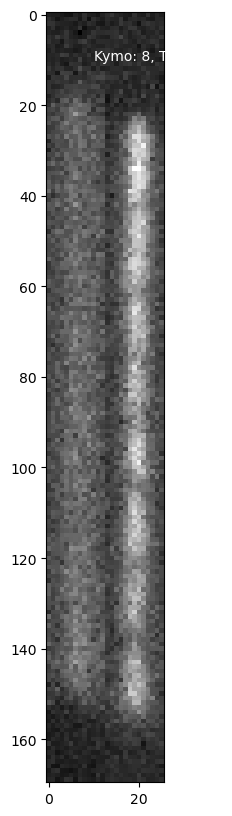

In [112]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

indices = np.arange(0, 2)
# print(indices)
channels = ["mCherry"]
trench_index = 7 # BAD: 1 (k30), GOOD: k30-20
kymo_index = 8
with h5py.File(
    "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/kymograph/kymograph_processed_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    # indices = list(range(0, 1, 1))
    # print(infile['0'].keys())
    for ch in channels:
        img = infile['0'][ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile['9'][ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure()
        plt.imshow(img, cmap="gray", aspect=1)
        # Annotate kymo and trench index
        plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
        plt.show()
        plt.close()

In [5]:
ff = tr.focus_filter(headpath)

In [6]:
ff.choose_filter_channel_inter()

interactive(children=(Dropdown(description='channel', options=('mCherry', None), value='mCherry'), Button(desc…

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/ipywidgets/widgets/interaction.py:43: DeprecationWarning: `ipykernel.pylab.backend_inline` is deprecated, directly use `matplotlib_inline.backend_inline`
  from ipykernel.pylab.backend_inline import flush_figures


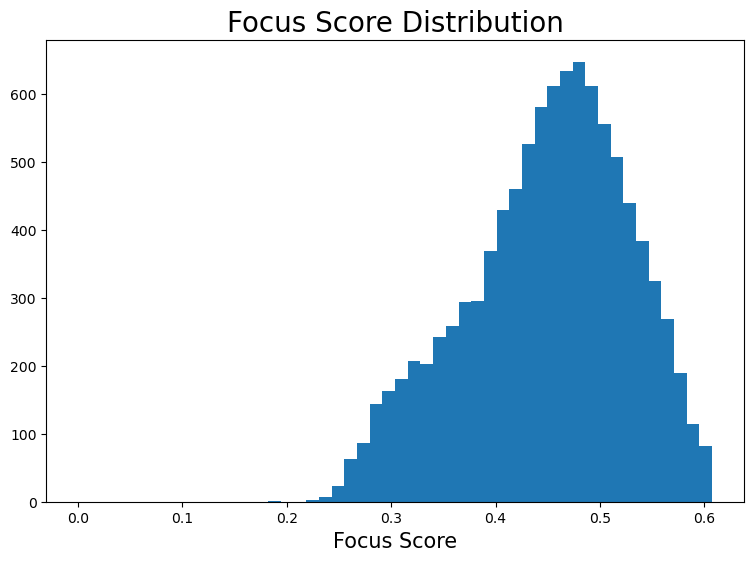

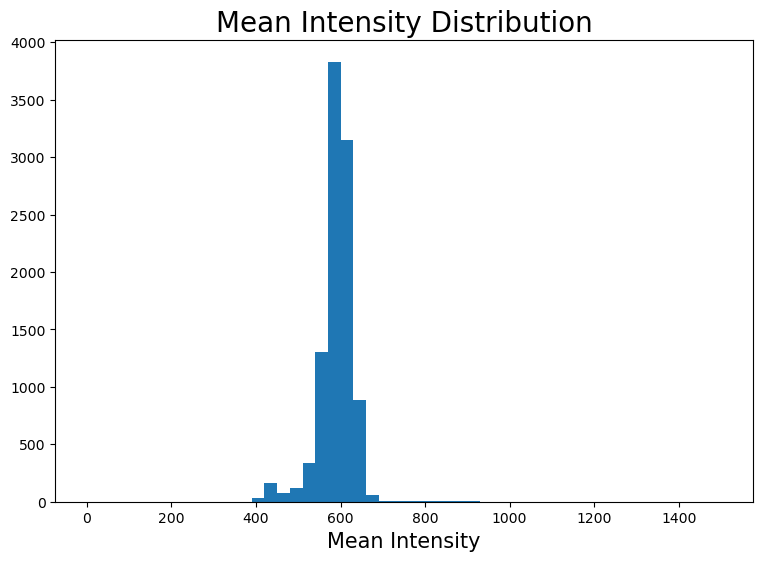

In [7]:
ff.plot_histograms(intensity_range=(0,1500))

In [8]:
ff.plot_focus_threshold_inter()

interactive(children=(FloatSlider(value=0.0, description='focus_thr', max=1.0, step=0.01), IntSlider(value=0, …

In [10]:
ff.write_param_file()

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
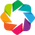

In [11]:
lane_overlay_handle = tr.lane_overlay(headpath,persist_data=True)
overlay = lane_overlay_handle.view_overlay(size=2500,vmin=0,vmax=4000)

In [12]:
overlay

BokehModel(combine_events=True, render_bundle={'docs_json': {'7c4e1cd0-7f95-47f8-9da5-cb13937caf88': {'version…

Task exception was never retrieved
future: <Task finished name='Task-207873' coro=<Callback.process_on_change() done, defined at /home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/holoviews/plotting/bokeh/callbacks.py:355> exception=UnsetValueError("figure(id='p55842', ...).inner_height doesn't have a value set")>
Traceback (most recent call last):
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/holoviews/plotting/bokeh/callbacks.py", line 374, in process_on_change
    msg[attr] = self.resolve_attr_spec(path, cb_obj)
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/holoviews/plotting/bokeh/callbacks.py", line 281, in resolve_attr_spec
    resolved = getattr(resolved, p, None)
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/bokeh/core/property/descriptors.py", line 283, in __get__
    raise UnsetValueError(f"{obj}.{self.name} doesn't have a value set")
bokeh.core.property.descriptors.UnsetValueError:

In [14]:
lane_overlay_handle.save_rows()

Eliminated Rows: []


##### Post-process Images

After the above step, kymographs will have been created for each `.hdf5` input file. They will now need to be reorganized <br>
into a new set of files such that each file has, at most, `trenches_per_file` trenches in each file.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [ ]:
dask_controller.shutdown()

In [17]:
kymoclust.post_process(dask_controller,trench_timepoints_per_file=10000)

/home/lag36/TrenchRipper/trenchripper/kymograph.py:1391: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  trenchid_filter = trench_group.apply(lambda x: np.sum((x[channel + " Focus Score"]>focus_threshold)&(x[channel + " Mean Intensity"]>intensity_threshold))>=num_above).compute()


Eliminating selected rows...


/home/lag36/TrenchRipper/trenchripper/kymograph.py:1516: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  fov_to_rows_series = outputdf.groupby("fov")["row"].apply(lambda x: sorted(list(set(x)))).compute().sort_index()


Number of timepoints per trench: 67
Number of trenches per file: 149


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 606.94 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 606.94 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide m

In [ ]:
dask_controller.shutdown()

In [18]:
print(1)

1


##### Check kymograph statistics

Run the next line to display some statistics from kymograph creation. The outputs are:

 - **fovs processed** : The number of FOVs successfully processed out of the total number of FOVs
 - **rows processed** : The number of rows of trenches processed out of the total number of rows
 - **trenches processed** : The number of trenches successfully processed
 - **row/fov** : The average number of rows successfully processed per FOV
 - **trenches/fov** : The average number of trenches successfully processed per FOV
 - **failed fovs** : A list of failed FOVs. Spot check these FOVs in the viewer to determine potential problems

In [19]:
kymoclust.kymo_report()

fovs processed: 756/760
rows processed: 7359
trenches processed: 593636
row/fov: 9.734126984126984
trenches/fov: 785.2328042328043
failed fovs: [136, 737, 597, 472]


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66]


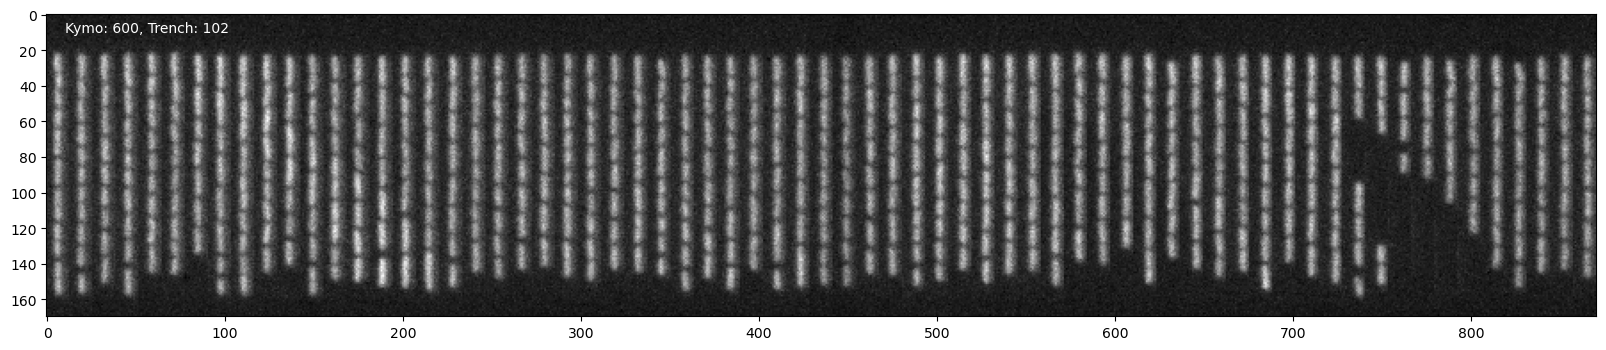

In [22]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

indices = np.arange(0, 67)
print(indices)
channels = ["mCherry"]
trench_index =102 # BAD: 1 (k30), GOOD: k30-20
kymo_index = 600
with h5py.File(
    "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/kymograph/kymograph_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    # indices = list(range(0, 1, 1))

    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure()
        plt.imshow(img, cmap="gray", aspect=1)
        # Annotate kymo and trench index
        plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
        plt.show()
        plt.close()

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66]


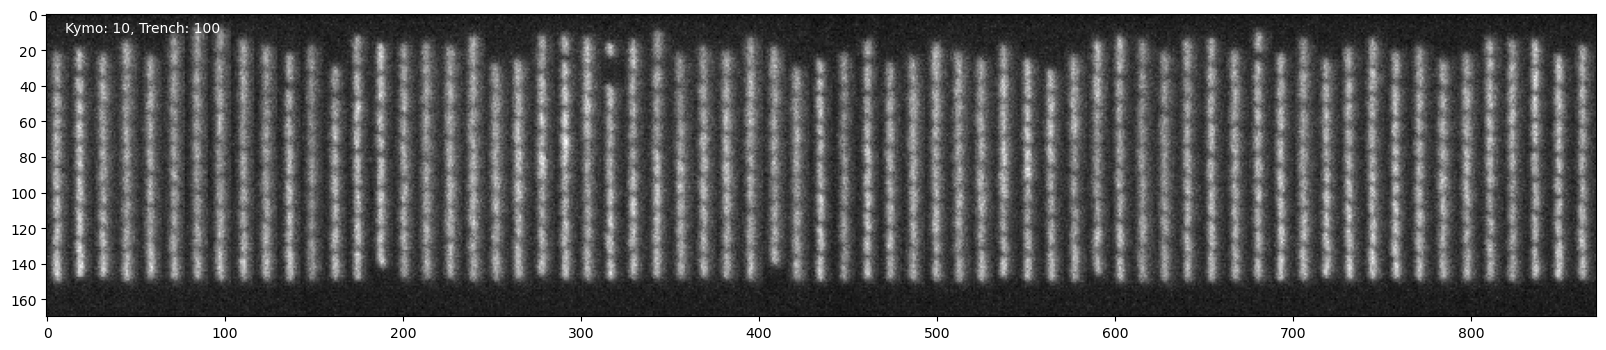

In [24]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

indices = np.arange(0, 67)
print(indices)
channels = ["mCherry"]
trench_index =100 # BAD: 1 (k30), GOOD: k30-20
kymo_index = 10
with h5py.File(
    "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/kymograph/kymograph_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    # indices = list(range(0, 1, 1))

    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure()
        plt.imshow(img, cmap="gray", aspect=1)
        # Annotate kymo and trench index
        plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
        plt.show()
        plt.close()

In [25]:
dask_controller.shutdown()

Done.


2024-12-01 09:49:05,405 - distributed.deploy.adaptive_core - INFO - Adaptive stop


## Fluorescence Segmentation

Now that you have copped your data into kymographs, we will now perform segmentation/cell detection <br>
on your kymographs. Currently, this pipeline only supports segmentation of fluorescence images; however, <br>
segmentation of transmitted light imaging techniques is in development.

The output of this step will be a set of `segmentation_[File #].hdf5` files stored in `headpath/fluorsegmentation`.<br>
The image data stored in these files takes the exact same form as the kymograph data, `(K,T,Y,X)` arrays <br>
where K is the trench index, T is time, and Y,X are the crop dimensions. These arrays are accessible using <br>
keys of the form `"[Trench Row Number]"`.

Since no metadata is generated by this step, it is possible to use another segmentation algorithm on the kymograph <br>
data. The output of segmentation must be split into `segmentation_[File #].hdf5` files, where `[File #]` agrees with the<br>
corresponding `kymograph_[File #].hdf5` file. Additionally, the `(K,T,Y,X)` arrays must be of the same shape as the <br>
kymograph arrays and accessible at the corresponding `"[Trench Row Number]"` key. These files must be placed into <br>
their own folder at `headpath/foldername`. This folder may then be used in later steps.

### Test Parameters

#### Typical parameters for mCherry single channel imaging at 20x

- Extra Mask Path: None
- 8 Bit Maximum: 6000
- Scale Fluorescence? False
- Scaling Percentile: 90
- Image Scaling Factor: 1.0
- Gaussian Kernel Sigma: 1.0
- Local Threshold Method: otsu
- Background Threshold Method: triangle
- Global Threshold: 18
- Local Window Size: 11
- Otsu Scaling: 0.9999999999999999
- Niblack K: 0.2
- Background Threshold Scaling: 1.0
- Minimum Object Size: 20
- Hessian Blur Sigma: 1.75
- Hessian Rolling Ball Size: 20
- Hessian Local Threshold Method: niblack
- Hessian Otsu Scaling: 0.9999999999999999
- Hessian Niblack K: 0.05
- Hessian Local Window Size: 7
- Distance Threshold: 1
- Border Buffer: 1
- Horizontal Border Only: False
- Segmentation Channel: mCherry

##### Initialize the interactive segmentation class

As a first step, initialize the `tr.fluo_segmentation_interactive` class that will be handling all steps of generating a segmentation. 

In [26]:
interactive_segmentation = tr.fluo_segmentation_interactive(headpath)

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


##### Choose channel to segment on

In [27]:
interactive_segmentation.choose_seg_channel_inter()

interactive(children=(Dropdown(description='seg_channel', options=('mCherry',), value='mCherry'), Dropdown(des…

#### Import data

Fill in 

You will need to tune the following `args` and `kwargs` (in order):

**fov_idx (int)** :

**n_trenches (int)** :

**t_range (tuple)** :

**t_subsample_step (int)** :

In [28]:
interactive_segmentation.import_array_inter()

interactive(children=(IntText(value=12, description='Number of trenches:'), IntRangeSlider(value=(0, 66), desc…

##### Process data

In [29]:
interactive_segmentation.plot_processed_inter()

interactive(children=(IntSlider(value=1000, description='8-bit Maximum:', max=65535, step=250), Dropdown(descr…

#### Determine Cell Mask Envelope

Fill in.

You will need to tune the following `args` and `kwargs` (in order):

**cell_mask_method (str)** : Thresholding method, can be a local or global Otsu threshold.

**cell_otsu_scaling (float)** : Scaling factor applied to determined threshold.

**local_otsu_r (int)** : Radius of thresholding kernel used in the local otsu thresholding.

In [32]:
interactive_segmentation.plot_cell_mask_inter()

interactive(children=(Dropdown(description='local_thr', options=('otsu', 'niblack', 'none'), value='otsu'), Dr…

In [38]:
interactive_segmentation.plot_eig_mask_inter()

interactive(children=(FloatSlider(value=2.0, description='Hessian Blur Sigma:', max=5.0, step=0.25), IntSlider…

In [39]:
interactive_segmentation.plot_dist_mask_inter()

interactive(children=(IntSlider(value=2, description='Distance Threshold:', max=20), Button(description='Run I…

In [33]:
import pickle as pkl
with open('/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/fluorescent_segmentation.par', 'rb') as f:
    x = pkl.load(f)
x

{'Extra Mask Path:': None,
 '8 Bit Maximum:': 6000,
 'Scale Fluorescence?': False,
 'Scaling Percentile:': 90,
 'Image Scaling Factor:': 1.0,
 'Gaussian Kernel Sigma:': 1.0,
 'Local Threshold Method:': 'otsu',
 'Background Threshold Method:': 'triangle',
 'Global Threshold:': 12,
 'Local Window Size:': 9,
 'Otsu Scaling:': 0.9999999999999999,
 'Niblack K:': 0.2,
 'Background Threshold Scaling:': 1.0,
 'Minimum Object Size:': 20,
 'Hessian Blur Sigma:': 1.75,
 'Hessian Rolling Ball Size:': 20,
 'Hessian Local Threshold Method:': 'niblack',
 'Hessian Otsu Scaling:': 0.9999999999999999,
 'Hessian Niblack K:': 0.5,
 'Hessian Local Window Size:': 7,
 'Distance Threshold:': 1,
 'Border Buffer:': 1,
 'Horizontal Border Only:': False,
 'Segmentation Channel:': 'mCherry'}

In [40]:
interactive_segmentation.plot_marker_mask_inter()

interactive(children=(FloatSlider(value=1.75, description='Hessian Blur Sigma:', max=5.0, step=0.25), IntSlide…

In [42]:
interactive_segmentation.process_results()

Extra Mask Path: None
8 Bit Maximum: 2000
Scale Fluorescence? False
Scaling Percentile: 90
Image Scaling Factor: 1.0
Gaussian Kernel Sigma: 1.0
Local Threshold Method: otsu
Background Threshold Method: triangle
Global Threshold: 20
Local Window Size: 11
Otsu Scaling: 0.9999999999999999
Niblack K: 0.2
Background Threshold Scaling: 1.0
Minimum Object Size: 20
Hessian Blur Sigma: 1.75
Hessian Rolling Ball Size: 20
Hessian Local Threshold Method: niblack
Hessian Otsu Scaling: 0.9999999999999999
Hessian Niblack K: 0.3
Hessian Local Window Size: 7
Distance Threshold: 1
Border Buffer: 0
Horizontal Border Only: False
Segmentation Channel: mCherry


In [43]:
interactive_segmentation.write_param_file()

In [ ]:
dask_controller.shutdown()

### Generate Segmentation

#### Start Dask Workers

In [44]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=500,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

50m
1:00:00


In [45]:
dask_controller.displaydashboard()

In [46]:
segment = tr.segment.fluo_segmentation_cluster(headpath, paramfile=True)

In [47]:
segment.dask_segment(dask_controller)

Done.


In [49]:
print(1)

1


#### Stop Dask Workers

In [50]:
dask_controller.shutdown()

Done.


2024-12-01 11:02:29,831 - distributed.deploy.adaptive_core - INFO - Adaptive stop


## Lineage Tracing

#### Typical parameters for mCherry single channel imaging at 20x

- Channels: ['mCherry']
- Closest N Objects to Consider: 2
- Mean Size Increase: 0.08
- Standard Deviation of Size Increase: 0.03
- Mean Position Increase: 0.1
- Standard Deviation of Position Increase: 0.05
- Cell Position Weight: 1.0
- Cell Size Weight: 1.0
- Cell Merging Weight: 0.0

In [51]:
import pickle as pkl
with open('/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/lineage_tracing.par', 'rb') as f:
    x = pkl.load(f)
x

{'Channels:': ['mCherry'],
 'Closest N Objects to Consider:': 2,
 'Size Measurement:': 'axis_major_length',
 'Mean Size Increase:': 0.08,
 'Standard Deviation of Size Increase:': 0.03,
 'Mean Position Increase:': 0.1,
 'Standard Deviation of Position Increase:': 0.05,
 'Cell Position Weight:': 1.0,
 'Cell Size Weight:': 1.0,
 'Cell Merging Weight:': 0.0}

In [2]:
import pickle as pkl
with open('/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Growth_Division/lineage_tracing.par', 'rb') as f:
    a = pkl.load(f)

a

{'Channels:': None,
 'Closest N Objects to Consider:': 2,
 'Size Measurement:': 'axis_major_length',
 'Mean Size Increase:': 0.12,
 'Standard Deviation of Size Increase:': 0.03,
 'Mean Position Increase:': 0.15,
 'Standard Deviation of Position Increase:': 0.05,
 'Cell Position Weight:': 1.0,
 'Cell Size Weight:': 1.0,
 'Cell Merging Weight:': 0.0}

### Test Parameters

In [7]:
score_function = tr.tracking.scorefn(
    headpath,
    "fluorsegmentation",
    size_attr='axis_major_length',
    u_size=0.08,
    sig_size=0.03,
    u_pos=0.1,
    sig_pos=0.05,
    w_merge=0.,
)

In [10]:
score_function.interactive_scorefn()

interactive(children=(IntSlider(value=0, description='trenchid', max=593635), IntRangeSlider(value=(0, 66), co…

In [11]:
print(1)

1


In [12]:
Tracking_Solver = tr.tracking.tracking_solver(
    headpath, "fluorsegmentation", ScoreFn=score_function, edge_limit=2,
)
data, orientation = score_function.output.result

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [13]:
Tracking_Solver.interactive_tracking(data, orientation)

interactive(children=(SelectMultiple(description='intensity_channel_list', options=('mCherry',), value=()), In…

In [14]:
Tracking_Solver.save_params()

Channels: ['mCherry']
Closest N Objects to Consider: 2
Size Measurement: axis_major_length
Mean Size Increase: 0.12
Standard Deviation of Size Increase: 0.03
Mean Position Increase: 0.15
Standard Deviation of Position Increase: 0.05
Cell Position Weight: 1.0
Cell Size Weight: 1.0
Cell Merging Weight: 0.0


### Generate Lineage Traces

In [15]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="1:00:00",
#     local=False,
#     n_workers=300,
#     n_workers_min=20,
#     memory="1GB",
#     death_timeout=60.,
#     working_directory=dask_wd,
# )
# dask_controller.startdask()
dask_controller = tr.trcluster.dask_controller(
    walltime="3:00:00",
    local=False,
    n_workers=500,
    n_workers_min=50,
    memory="3GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

170m
3:00:00


In [16]:
dask_controller.displaydashboard()

In [17]:
# Tracking_Solver = tr.tracking.tracking_solver(
#     headpath, "fluorsegmentation", paramfile=True, volume_estimation=True, props_list=['area','major_axis_length','minor_axis_length'],
#     props_to_unpack={},pixel_scaling_factors={'area': 2, 'major_axis_length': 1,'minor_axis_length': 1},intensity_props_list=['mean_intensity'] 
# )

# Tracking_Solver = tr.tracking.tracking_solver(
#     headpath, 
#     "fluorsegmentation", 
#     paramfile=True, 
#     size_estimation=True,
#     size_estimation_method='Perimeter/Area',
#     props_list=['area'], 
#     props_to_unpack={},
#     pixel_scaling_factors={'area': 2},
#     intensity_props_list=['mean_intensity'] 
# )

Tracking_Solver = tr.tracking.tracking_solver(
    headpath,
    "fluorsegmentation",
    paramfile=True,
    size_estimation=True,
    size_estimation_method="Perimeter/Area",
    # props_list=["area", "bbox", "centroid"],
    props_list=["area", "major_axis_length", "minor_axis_length"],
    # props_to_unpack={
    #     "bbox": ("bbox_min_row", "bbox_min_col", "bbox_max_row", "bbox_max_col"),
    #     "centroid": ("centroid_y", "centroid_x"),
    # },
    pixel_scaling_factors={
        "area": 2,
        "major_axis_length": 1,
        "minor_axis_length": 1
        # "bbox_min_row": 1,
        # "bbox_min_col": 1,
        # "bbox_max_row": 1,
        # "bbox_max_col": 1,
        # "centroid_y": 1,
        # "centroid_x": 1,
    },
    intensity_props_list=["mean_intensity"],
)

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [18]:
Tracking_Solver.compute_all_lineages(dask_controller,entries_per_partition = 100000, overwrite=True)

Kymograph files per partition: 11
Done.
Done.
# Trenches Processed / # Trenches = 473160/593636


In [20]:
dask_controller.shutdown()

Done.


2024-12-03 00:24:22,979 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [19]:
print(1)

1


In [ ]:
print(1)

In [1]:
dask_controller.shutdown()

NameError: name 'dask_controller' is not defined

# Part 2: Barcodes

#### Specify Paths

Begin by defining the directory in which all processing will be done, as well as the initial nd2 file we will be <br>processing. This line should be run everytime you open a new python kernel.

The format should be: `headpath = "/path/to/folder"` and `nd2file = "/path/to/file.nd2"`

For example:
```
headpath = "/n/scratch2/de64/2019-05-31_validation_data"
nd2file = "/n/scratch2/de64/2019-05-31_validation_data/Main_Experiment.nd2"
```

Ideally, these files should be placed in a storage location with relatively fast I/O

In [4]:
headpath = "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Barcodes"
hdf5inputpath = "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/run/"

## Extract to hdf5 files

In this section, we will be extracting our image data. Currently this notebook only supports `.nd2` format; however <br>there are `.tiff` extractors in the TrenchRipper source files that are being added to `Master.ipynb` soon.

In the abstract, this step will take a single `.nd2` file and split it into a set of `.hdf5` files stored in <br>`headpath/hdf5`. Splitting the file up in this way will facilitate quick procesing in later steps. Each field of <br>view will be split into one or more `.hdf5` files, depending on the number of images per file requested (more on <br>this later). 

To keep track of which output files correspond to which FOVs, as well as to keep track of experiment metadata, the <br>extractor also outputs a `metadata.hdf5` file in the `headpath` folder. The data from this step is accessible in <br>that `metadata.hdf5` file under the `global` key. If you would like to look at this metadata, you may use the <br>`tr.utils.pandas_hdf5_handler` to read from this file. Later steps will add additional metadata under different <br>keys into the `metadata.hdf5` file.

#### Start Dask Workers

First, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [4]:
dask_controller = tr.trcluster.dask_controller(
    walltime="3:00:00",
    local=False,
    n_workers=300,
    n_workers_min=20,
    memory="4GB",#3GB next time
    working_directory=dask_wd,
)
dask_controller.startdask()

170m
3:00:00


In [5]:
dask_controller.daskclient

Connection method: Cluster object,Cluster type: dask_jobqueue.SLURMCluster
Dashboard: http://10.120.16.162:8787/status,
Dashboard: http://10.120.16.162:8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://10.120.16.162:41110,Workers: 0
Dashboard: http://10.120.16.162:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


##### Perform Extraction

Now that we have our cluster scheduler spun up, it is time to convert files. This will be handled by the <br>`hdf5_extractor` object. This extractor will pull up each FOV and split it such that each derived `.hdf5` file <br>contains, at maximum, N timepoints of that FOV per file. The image data stored in these files takes the <br>form of `(N,Y,X)` arrays that are accessible using the desired channel name as a key. 

The arguments for this extractor are:

 - **nd2file** : The filepath to the `.nd2` file you intend to extract.
 
 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **tpts_per_file** : The maximum number of timepoints stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **ignore_fovmetadata** : Used when `.nd2` data is corrupted and does not possess records for stage positions or <br>timepoints. Only set `False` if the extractor throws errors on metadata handling.

 - **nd2reader_override** : Overrides values in metadata recovered using the `nd2reader`. Currently set to <br>`{"z_levels":[],"z_coordinates":[]}` by default to correct a known issue where z coordinates are mistakenly <br>interpreted as a z stack. See the [nd2reader](https://rbnvrw.github.io/nd2reader/) documentation for more info.

In [6]:
hdf5_extractor = tr.marlin_extractor(hdf5inputpath, headpath, pixel_microns=0.105951961895293*2, metaparsestr='metadata_{timepoint:d}.hdf5')

##### Extraction Parameters

Here, you may set the time interval you want to extract. Useful for cropping data to the period exhibiting the dynamics of interest.

Optionally take notes to add to the `metadata.hdf5` file. Notes may also be taken directly in this notebook.

In [7]:
hdf5_extractor.inter_set_params()

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/TrenchRipper/trenchripper/utils.py:86: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block2_values] [items->Index(['channel_paths', 'config'], dtype='object')]

  store.put(key, df)
/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


interactive(children=(SelectMultiple(description='fov_list', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12…

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/ipywidgets/widgets/interaction.py:43: DeprecationWarning: `ipykernel.pylab.backend_inline` is deprecated, directly use `matplotlib_inline.backend_inline`
  from ipykernel.pylab.backend_inline import flush_figures


#### List of paths to flat fields


- dark_outputpath =  /home/de64/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/40x_DarkImage.tiff
- Cy5_outputpath =   /home/de64/scratch/de64/sync_folder/2021-10-21_Flat_Fields/Cy5-Penta_20x_Ph2_flatfield.tiff
- Cy7_outputpath =   /home/de64/scratch/de64/sync_folder/2021-10-21_Flat_Fields/Cy7-Penta_20x_Ph2_flatfield.tiff
- GFP_outputpath =   /home/de64/scratch/de64/sync_folder/2021-10-21_Flat_Fields/RFP-Penta_20x_Ph2_flatfield.tiff

In [ ]:
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff

In [8]:
hdf5_extractor.inter_set_flatfieldpaths()

##### Begin Extraction 

Running the following line will start the extraction process. This may be monitored by examining the `Dask Dashboard` <br> under the link displayed earlier. Once the computation is complete, move to the next line.

This step may take a long time, though it is possible to speed it up using additional workers.

In [9]:
hdf5_extractor.extract(dask_controller)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/TrenchRipper/trenchripper/utils.py:86: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block2_values] [items->Index(['channel_paths', 'config'], dtype='object')]

  store.put(key, df)
/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'

In [ ]:
dask_controller.shutdown()

##### Shutdown Dask

Once extraction is complete, it is likely that you will want to shutdown your `dask_controller` if you are on a <br>
cluster. This is because the specifications of the current `dask_controller` will not be optimal for later steps. <br>
To do this, run the following line and wait for it to complete. If it hangs, interrupt your kernel and re-run it. <br>
If this also fails to shutdown your workers, you will have to manually shut them down using `scancel` in a terminal.

## Kymographs

Now that you have extracted your data into a series of `.hdf5` files, we will now perform identification and cropping <br>of the individual trenches/growth channels present in the images. This algorithm assumes that your growth trenches <br>are vertically aligned and that they alternate in their orientation from top to bottom. See the example image for the <br>correct geometry:

![example_image](./resources/example_image.jpg)

The output of this step will be a set of `.hdf5` files stored in `headpath/kymograph`. The image data stored in these <br>files takes the form of `(K,T,Y,X)` arrays where K is the trench index, T is time, and Y,X are the crop dimensions. <br>These arrays are accessible using keys of the form `"[Image Channel]"`. For example, looking up phase channel <br>data of trenches in the topmost row of an image will require the key `"Phase"`

### Test Parameters

#### Typical parameters for 20x FISH decoding

- Y Percentile 99
- Y Foreground Percentile 65
- Y Smoothing Kernel 51
- Y Percentile Threshold 0.5
- Minimum Trench Length 80
- Midpoint Distance Tolerance 50
- Y Padding 20
- Trench Length 130
- Orientation Detection Method 1
- Expected Number of Rows (Manual Orientation Detection) 10
- Alternate Orientation True
- Alternate Orientation Over Rows? False
- Use Median Drift? False
- X Percentile 50
- X Background Kernel 21
- X Smoothing Kernel 5
- Otsu Threshold Scaling 0.0
- Minimum X Threshold 500
- Trench Width 14
- Trench Presence Threshold 1.0
- All Channels ['BF', 'Cy7', 'Cy5', 'RFP']
- Filter Channel None
- Invert False

##### Initialize the interactive kymograph class

As a first step, initialize the `tr.interactive.kymograph_interactive` class that will be help us choose the <br>parameters we will use to generate kymographs. 

In [10]:
interactive_kymograph = tr.kymograph_interactive(headpath)

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [ ]:
viewer = tr.hdf5_viewer(headpath,persist_data=False)

##### Examine Images

Here you can manually inspect images before beginning parameter tuning.

In [ ]:
viewer.view(width=1200)

You will now want to select a few test FOVs to try out parameters on, the channel you want to detect trenches on, and <br>the time interval on which you will perform your processing.

The arguments for this step are:

- **seg_channel (string)** : The channel name that you would like to segment on.

- **invert (list)** : Whether or not you want to invert the image before detecting trenches. By default, it is assumed that <br>the trenches have a high pixel intensity relative to the background. This should be the case for Phase Contrast and <br>Fluorescence Imageing, but may not be the case for Brightfield Imaging, in which case you will want to invert the image.

- **fov_list (list)** : List of integers corresponding to the FOVs that you wish to make test kymographs of.

- **t_subsample_step (int)** : Step size to be used for subsampling input files in time, recommend that subsampling results in <br>between 5 and 10 timepoints for quick processing.

Hit the "Run Interact" button to lock in your parameters. The button will become transparent briefly and become solid again <br>when processing is complete. After that has occured, move on to the next step. 

In [31]:
interactive_kymograph.import_hdf5_interactive()

interactive(children=(Dropdown(description='seg_channel', options=('BF', 'Cy5', 'RFP'), value='BF'), Dropdown(…

##### Tune "trench-row" detection hyperparameters

The kymograph code begins by detecting the positions of trench rows in the image as follows:

1. Reducing each 2D image to a 1D signal along the y-axis by computing the qth percentile of the data along the x-axis
2. Smooth this signal using a median kernel
3. Normalize the signal by linearly scaling 0. and 1. to the minimum and maximum, respectively
4. Use a set threshold to determine the trench row poisitons

The arguments for this step are:

 - **y_percentile (int)** : Percentile to use for step 1.

 - **smoothing_kernel_y_dim_0 (int)** : Median kernel size to use for step 2.

 - **y_percentile_threshold (float)** : Threshold to use in step 4.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line.

In [32]:
interactive_kymograph.preview_y_precentiles_interactive()

interactive(children=(IntSlider(value=99, description='y_percentile'), IntSlider(value=80, description='y_fore…

In [33]:
interactive_kymograph.preview_y_precentiles_consensus_interactive()

interactive(children=(IntSlider(value=50, description='n_fovs', step=5), Dropdown(description='Y Consensus Ena…

##### Tune "trench-row" cropping hyperparameters

Next, we will use the detected rows to perform cropping of the input image in the y-dimension:

1. Determine edges of trench rows based on threshold mask.
2. Filter out rows that are too small.
3. Use the remaining rows to compute the drift in y in each image.
4. Apply the drift to the initally detected rows to get rows in all timepoints.
5. Perform cropping using the "end" of the row as reference (the end referring to the part of the trench farthest from <br>the feeding channel).

Step 5 performs a simple algorithm to determine the orientation of each trench:

```
row_orientations = [] # A list of row orientations, starting from the topmost row
if the number of detected rows == 'Number of Rows': 
    row_orientations.append('Orientation')
elif the number of detected rows < 'Number of Rows':
    row_orientations.append('Orientation when < expected rows')
for row in rows:
    if row_orientations[-1] == downward:
        row_orientations.append(upward)
    elif row_orientations[-1] == upward:
        row_orientations.append(downward)
```

Additionally, if the device tranches face a single direction, alternation of row orientation may be turned off by setting the<br> `Alternate Orientation?` argument to False. The `Use Median Drift?` argument, when set to True, will use the<br> median drift in y across all FOVs for drift correction, instead of doing drift correction independently for all FOVs. <br>This can be useful if there are a large fraction of FOVs which are failing drift correction. Note that `Use Median Drift?` <br>sets this behavior for both y and x drift correction.

The arguments for this step are:

 - **y_min_edge_dist (int)** : Minimum row length necessary for detection (filters out small detected objects).

 - **padding_y (int)** : Padding to add to the end of trench row when cropping in the y-dimension.

 - **trench_len_y (int)** : Length from the end of each trench row to the feeding channel side of the crop.

 - **Number of Rows (int)** : The number of rows to expect in your image. For instance, two in the example image.
 
 - **Alternate Orientation? (bool)** : Whether or not to alternate the orientation of consecutive rows.

 - **Orientation (int)** : The orientation of the top-most row where 0 corresponds to a trench with a downward-oriented trench <br>opening and 1 corresponds to a trench with an upward-oriented trench opening.

 - **Orientation when < expected rows(int)** : The orientation of the top-most row when the number of detected rows is less than <br>expected. Useful if your trenches drift out of your image in some FOVs.
 
 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.

 - **images_per_row(int)** : How many images to output per row for this widget.

Running the following widget will display y-cropped images for each fov and timepoint.

In [34]:
interactive_kymograph.preview_y_crop_interactive()

interactive(children=(IntSlider(value=50, description='y_min_edge_dist', max=1000, min=5, step=5), IntSlider(v…

##### Tune trench detection hyperparameters

Next, we will detect the positions of trenchs in the y-cropped images as follows:

1. Reducing each 2D image to a 1D signal along the x-axis by computing the qth percentile of the data along the y-axis.
2. Determine the signal background by smoothing this signal using a large median kernel.
3. Subtract the background signal.
4. Smooth the resultant signal using a median kernel.
5. Use an [otsu threhsold](https://imagej.net/Auto_Threshold#Otsu) to determine the trench midpoint poisitons.

After this, x-dimension drift correction of our detected midpoints will be performed as follows:

6. Begin at t=1
7. For $m \in \{midpoints(t)\}$ assign $n \in \{midpoints(t-1)\}$ to m if n is the closest midpoint to m at time $t-1$,<br>
points that are not the closest midpoint to any midpoints in m will not be mapped.
8. Compute the translation of each midpoint at time.
9. Take the average of this value as the x-dimension drift from time t-1 to t.

The arguments for this step are:

 - **t (int)** : Timepoint to examine the percentiles and threshold in.

 - **x_percentile (int)** : Percentile to use for step 1.

 - **background_kernel_x (int)** : Median kernel size to use for step 2.

 - **smoothing_kernel_x (int)** : Median kernel size to use for step 4.

 - **otsu_scaling (float)** : Scaling factor to apply to the threshold determined by Otsu's method.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line. In addition, it will display the detected midpoints for each of your timepoints. <br>If there is too much sparsity, or discontinuity, your drift correction will not be accurate.

In [ ]:
Y Percentile 99
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.2
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 130
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? True
Consensus Orientations None
Consensus Midpoints None
X Percentile 50
X Background Kernel 21
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 50
Trench Width 8
Trench Presence Threshold 1.0
All Channels ['BF', 'RFP', 'Cy5']
Filter Channel None
Invert False

In [16]:
dask_controller.shutdown()

Done.


2024-12-01 20:32:37,491 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [35]:
interactive_kymograph.preview_x_percentiles_interactive()

interactive(children=(IntSlider(value=0, description='t', max=4), IntSlider(value=85, description='x_percentil…

##### Tune trench cropping hyperparameters

Trench cropping simply uses the drift-corrected midpoints as a reference and crops out some fixed length around them <br>
to produce an output kymograph. **Note that the current implementation does not allow trench crops to overlap**. If your<br>
trench crops do overlap, the error will not be caught here, but will cause issues later in the pipeline. As such, try <br>
to crop your trenches as closely as possible. This issue will be fixed in a later update.

The arguments for this step are:

 - **trench_width_x (int)** : Trench width to use for cropping.

 - **trench_present_thr (float)** : Trenches that appear in less than this percent of FOVs will be eliminated from the dataset.<br>
If not removed, missing positions will be inferred from the image drift.

 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.


Running the following widget will display a random kymograph for each row in each fov and will also produce midpoint plots <br>showing retained midpoints

In [37]:
interactive_kymograph.preview_kymographs_interactive()

interactive(children=(IntSlider(value=30, description='trench_width_x', max=1000, min=2, step=2), FloatSlider(…

##### Export and save hyperparameters

Run the following line to register and display the parameters you have selected for kymograph creation.

In [38]:
interactive_kymograph.process_results()

Y Percentile 70
Y Foreground Percentile 60
Y Smoothing Kernel 49
Y Percentile Threshold 0.5
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 130
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? False
Consensus Orientations None
Consensus Midpoints None
X Percentile 55
X Background Kernel 21
X Smoothing Kernel 9
Otsu Threshold Scaling 0.0
Minimum X Threshold 50
Trench Width 8
Trench Presence Threshold 1.0
All Channels ['BF', 'Cy5', 'RFP']
Filter Channel None
Invert False


If you are satisfied with the above parameters, run the following line to write these parameters to disk at `headpath/kymograph.par`<br>
This file will be used to perform kymograph creation in the next section.

In [39]:
interactive_kymograph.write_param_file()

### Generate Kymograph

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [40]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=300,
    n_workers_min=20,
    memory="4GB",#
    working_directory=dask_wd,
)
dask_controller.startdask()

50m
1:00:00


In [41]:
dask_controller.displaydashboard()

##### Perform Kymograph Cropping

Now that we have our cluster scheduler spun up, we will extract kymographs using the parameters stored in `headpath/kymograph.par`. <br>
This will be handled by the `kymograph_cluster` object. This will detect trenches in all of the files present in `headpath/hdf5` that <br>
you created in the first step. It will then crop these trenches and place the crops in a series of `.hdf5` files in `headpath/kymograph`. <br>
These files will store image data in the form of `(K,T,Y,X)` arrays where K is the trench index, T is time and Y,X are the image dimensions <br>
of the crop.

The arguments for this step are:

 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **trenches_per_file** : The maximum number of trenches stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **paramfile** : Set to true if you want to use parameters from `headpath/kymograph.par` Otherwise, you will have to specify <br>
 parameters as direct arguments to `kymograph_cluster`.

In [42]:
kymoclust = tr.kymograph.kymograph_cluster(
    headpath=headpath, paramfile=True
)

##### Begin Kymograph Cropping 

Running the following line will start the cropping process. This may be monitored by examining the `Dask Dashboard` <br>
under the link displayed earlier. Once the computation is complete, move to the next line.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [43]:
kymoclust.generate_kymographs(dask_controller)

/home/lag36/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map or apply function that you are using.
  Before: .apply(func)
  After:  .apply(func, meta=(None, 'int64'))

  warnings.warn(meta_warning(meta))
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 20.94 MiB.
This may cause some slowdown.
Consider scattering data ahea

In [18]:
dask_controller.shutdown()

Done.


2024-11-25 19:14:45,651 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [44]:
ff = tr.focus_filter(headpath)

In [45]:
ff.choose_filter_channel_inter()

interactive(children=(Dropdown(description='channel', options=(None,), value=None), Button(description='Run In…

In [ ]:
ff.plot_histograms()

In [46]:
ff.plot_focus_threshold_inter()

No Channel Selected


In [47]:
ff.write_param_file()

##### Post-process Images

After the above step, kymographs will have been created for each `.hdf5` input file. They will now need to be reorganized <br>
into a new set of files such that each file has, at most, `trenches_per_file` trenches in each file.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [48]:
kymoclust.post_process(dask_controller,trench_timepoints_per_file=10000)

Number of timepoints per trench: 15
Number of trenches per file: 666


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 311.78 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 311.78 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide m

##### Check kymograph statistics

Run the next line to display some statistics from kymograph creation. The outputs are:

 - **fovs processed** : The number of FOVs successfully processed out of the total number of FOVs
 - **rows processed** : The number of rows of trenches processed out of the total number of rows
 - **trenches processed** : The number of trenches successfully processed
 - **row/fov** : The average number of rows successfully processed per FOV
 - **trenches/fov** : The average number of trenches successfully processed per FOV
 - **failed fovs** : A list of failed FOVs. Spot check these FOVs in the viewer to determine potential problems

In [49]:
kymoclust.kymo_report()

fovs processed: 757/760
rows processed: 7570
trenches processed: 1362123
row/fov: 10.0
trenches/fov: 1799.3698811096433
failed fovs: [492, 717, 654]


##### Shutdown Dask

Once cropping is complete, it is likely that you will want to shutdown your `dask_controller` if you are on a <br>
cluster. This is because the specifications of the current `dask_controller` will not be optimal for later steps. <br>
To do this, run the following line and wait for it to complete. If it hangs, interrupt your kernel and re-run it. <br>
If this also fails to shutdown your workers, you will have to manually shut them down using `scancel` in a terminal.

In [50]:
dask_controller.shutdown()

Done.


2024-12-01 21:18:20,865 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [51]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

indices = np.arange(0, 15)
print(indices)
channels = ["BF", "RFP", "Cy5"]

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


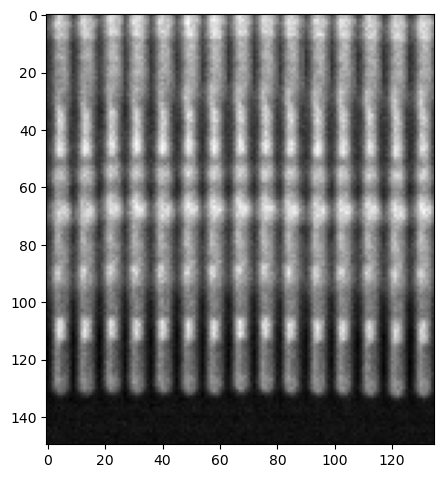

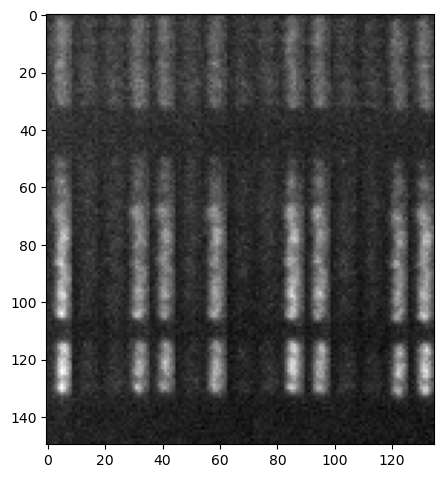

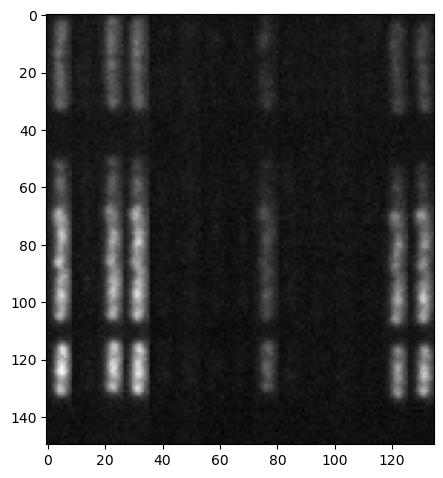

In [58]:
trench_index = 451 # BAD: 1 (k30), GOOD: k30-20
kymo_index = 0
with h5py.File(
    "/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Barcodes/kymograph/kymograph_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure(figsize = (5,10))
        plt.imshow(img, cmap="gray", aspect=1)
        plt.show()
        plt.close()

In [9]:
import pandas as pd

In [10]:
# Add fiducial sequences to the 
# Import nanopore data
df_nanopore = pd.read_csv("/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/lLAG8_final_df.tsv", sep="\t")

In [ ]:
df_nanopore

## FISH Analysis

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [60]:
dask_controller.shutdown()

Done.


2024-11-25 21:10:02,491 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [ ]:
dask_controller.reset_worker_memory()

In [5]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=200, #100,
    n_workers_min=20,
    memory="8GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

50m
1:00:00


#### Get Barcode Signal (Percentile Function)

In [60]:
import numpy as np

tr.get_all_image_measurements(
    dask_controller,
    headpath,
    headpath + "/percentiles",
    ["RFP","Cy5"],
    "98th Percentile",
    np.percentile,
    98)

#### Determine Barcodes

In [63]:
dask_controller.shutdown()

Done.


2024-11-25 21:43:38,156 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [6]:
# Need to remove cycles 10 and 11 both channels
fish_test = tr.fish_analysis(
    headpath,
    "/home/lag36/scratch/lag36/2024-11-22_lLAG10_Nanopore/lLAG10_final_df_fiducials.tsv",
    # "/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/lLAG8_final_df.tsv",
    # remove_bit_list=[1,10], # Wrong way (?)
    # ACTUAL BIT NUMBER
    remove_bit_list=[],
    # remove_bit_list=[1],
    # POSITION IN CYCLE ORDER
    hamming_thr=2,#1, # 0 is more conservative, don't go above 2.
    channel_names=["RFP 98th Percentile", "Cy5 98th Percentile"],
    # Places are the order of imaging, first RFP cycles 1 - 15, then Cy5 cycles 1 - 15
    # Numbers are the bit order in the physical RNA barcode
    cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16,\
                  2,3,8,9,14,15,20,21,26,27,17,22,23,28,29], 
    subsample=200000#20000
)

In [7]:
fish_test.plot_signal_threshold_inter()

interactive(children=(FloatSlider(value=39.99764368377027, description='Signal Threshold:', step=0.5), Button(…

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/ipywidgets/widgets/interaction.py:43: DeprecationWarning: `ipykernel.pylab.backend_inline` is deprecated, directly use `matplotlib_inline.backend_inline`
  from ipykernel.pylab.backend_inline import flush_figures


In [63]:
fish_test.get_bit_thresholds()

KeyboardInterrupt: 

In [45]:
# fish_test.bit_threshold_list = 

In [46]:
test = fish_test.kymograph_metadata_subsample.reset_index(drop=False)

In [13]:
bit_thresh_list = fish_test.bit_threshold_list

In [8]:
bit_thresh_list = [2200, # 1
 2000, #2 
 2200, #3
 2200, #4
 2200, #5
 2000, #6
 2200, #7
 2000, #8
 2200,#9
 2200, #10
 2200, #11
 2200, #12
 2000, #13
 2000, #14
 2200, #15
 4200, #1
 4200, #2
 5000, #3
 5000, #4
 4500, #5
 4000, #6
 4000, #7
 4000, #8
 3600, #9
 3600, #10
 4000, #11
 4000, #12
 4000, #13
 4000, #14
 4000] #15

In [9]:
fish_test.bit_threshold_list = bit_thresh_list

In [10]:
fish_test.plot_bit_threshold_inter()

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/ipywidgets/widgets/widget.py:503: DeprecationWarning: Passing unrecognized arguments to super(IntText).__init__(min=0, max=10000000).
object.__init__() takes exactly one argument (the instance to initialize)
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super().__init__(**kwargs)


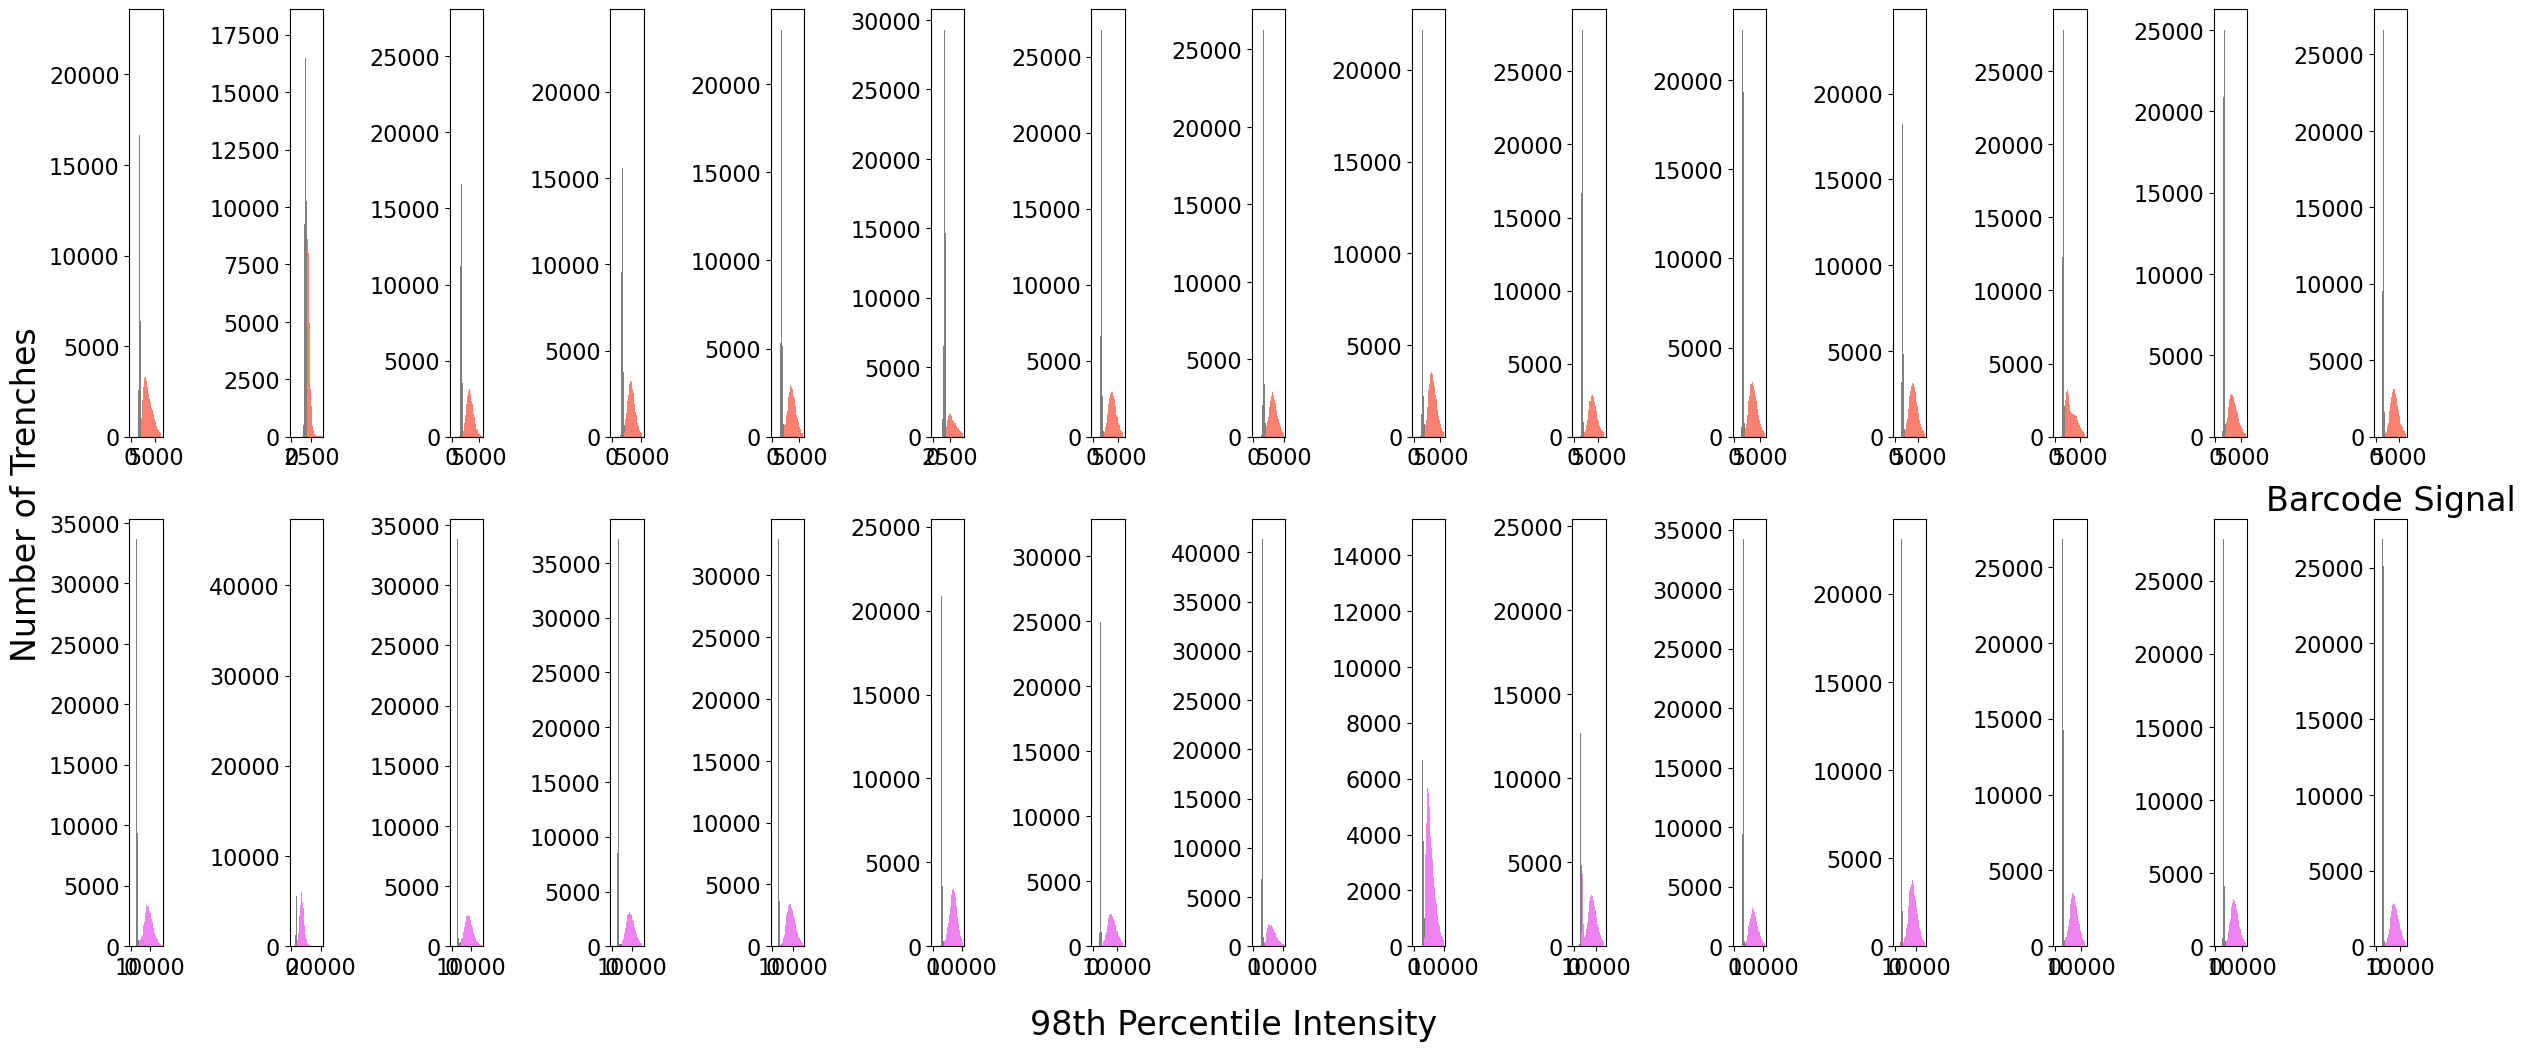

In [11]:
fish_test.export_bit_thresholds()

In [12]:
fish_test.nanoporedfpath

'/home/lag36/scratch/lag36/2024-11-22_lLAG10_Nanopore/lLAG10_final_df_fiducials.tsv'

In [13]:
fish_test.output_barcode_df(dask_controller,'/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Barcodes/barcode_output_df_fiducials_hamming-2_rm-bit-none.hdf5')

Getting Barcode df...


/home/lag36/TrenchRipper/trenchripper/marlin.py:732: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  barcodes = trench_group.apply(lambda x: list(itertools.chain.from_iterable([x[channel].tolist()\
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 444.70 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


Getting Nanopore df...
Merging...


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/array/routines.py:443: PerformanceWarning: Increasing number of chunks by factor of 10
  out = blockwise(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/array/routines.py:443: PerformanceWarning: Increasing number of chunks by factor of 10
  out = blockwise(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 23.08 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 23.08 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/zarr/creation.py:295: UserWarning: ignoring keyword argument 'inline_array'
  warn(

In [ ]:
import pandas as pd
df_2_1 = pd.read_hdf('/home/lag36/scratch/lag36/2024-10-31_lLAG8_MBM_Run-2/Barcodes/barcode_output_df_fiducials_hamming-2_rm-bit-1.hdf5')
df_2_1


In [16]:
dask_controller.shutdown()

Done.


2024-11-29 17:06:25,705 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [14]:
import pandas as pd
df = pd.read_hdf('/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Barcodes/barcode_output_df_fiducials_hamming-2_rm-bit-none.hdf5')
df

,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
0,114,"[2017.0, 2098.12, 3091.12, 1951.0, 1945.02, 19...",011000011110001110100001111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,381.0,3,...,BSU_28740,694.0,araP,GTCAGCACATATACGGTTAC,GTAACCGTATATGTGCTGAC,nonessential,1.0,7356.0,011110100100000011010011110110,43065
1,701,"[1857.04, 1830.02, 2937.02, 3041.0, 1813.0, 17...",001100001001000110010001110110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,822M1D3M1D264M,NaN,222.0,4,...,BSU_30560,1556.0,pckA,AGGGCCGCCTGCCTGGGCGA,TCGCCCAGGCAGGCGGCCCT,nonessential,1.0,7839.0,001101110000001001000001101110,19468
2,1540,"[1928.06, 2139.02, 1914.06, 1848.02, 3644.02, ...",010010000101001010100011101111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,512.0,4,...,BSU_31200,1080.0,rhaB,AGGCAAGTTCGCCTGCAGTA,TACTGCAGGCGAACTTGCCT,nonessential,1.0,8022.0,010101000100100010000111010111,28391
3,1552,"[1914.12, 1881.0, 1893.1, 1883.08, 4128.04, 34...",000011000111111011101001100101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,990.0,4,...,BSU_18280,311.0,yngK,GGGGTCCTTCCCTTGGACAC,GTGTCCAAGGGAAGGACCCC,nonessential,1.0,4927.0,000111001111110110000001011101,9342
4,2242,"[2093.02, 2109.02, 3291.06, 2049.02, 3840.12, ...",011011101000100100111011001101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,594M1D496M,NaN,840.0,4,...,BSU_04690,317.0,rsbT,ATCCATCAGCCTTTTGACCC,GGGTCAAAAGGCTGATGGAT,nonessential,1.0,1161.0,001000100110111100100111101001,11404
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
240461,1354352,"[4754.18, 1880.02, 3678.22, 1850.0, 1779.06, 1...",101000010010100101111101011001,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,607.0,4,...,BSU_19270,204.0,yozN,AAGAGGCCGGAGAATCAATT,AATTGATTCTCCGGCCTCTT,nonessential,1.0,5247.0,101010101110001101011010000001,61368
240462,1354437,"[1932.04, 1931.0, 4117.1, 1931.04, 4625.02, 18...",001010001110011001001101110100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,548.0,4,...,BSU_26960,46.0,yraF,AATGTAGTGTCTGCTAGTTC,GAACTAGCAGACACTACATT,nonessential,1.0,6899.0,000010101001100111001001111000,3299
240463,1355423,"[1879.08, 2025.04, 2903.02, 1854.02, 3042.12, ...",011011110111001111111011011111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,205.0,5,...,BSU_34040,924.0,lutB,GGATACATTGCAGCACAGAC,GTCTGTGCTGCAATGTATCC,nonessential,1.0,8826.0,011111101100111111110111010011,44840
240464,1355786,"[3210.2999999999997, 1949.04, 1867.04, 2584.16...",100100110011100100111001000010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,507.0,3,...,BSU_17100,555.0,pksC,ACGCGCCGCTTACGTTTAAG,CTTAAACGTAAGCGGCGCGT,nonessential,1.0,4588.0,101011010110001100110000000010,62373


In [15]:
import pandas as pd
df = pd.read_hdf('/home/lag36/scratch/lag36/2024-11-13_lLAG10_MBM_Run-1/Barcodes/barcode_output_df_fiducials_hamming-2_rm-bit-none.hdf5')
df

,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
0,82,"[2024.08, 2086.0, 1996.0, 1968.08, 3015.02, 19...",010010000011111011010001100111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,207.0,3,...,BSU_24180,568.0,yqiK,AGTACTTCATCTGTGACCCC,GGGGTCACAGATGAAGTACT,nonessential,1.0,6092.0,010111001011101010000001001111,31164
1,450,"[5766.44, 2150.06, 4467.16, 2122.08, 2097.02, ...",111001100100110100011010111010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,329.0,4,...,BSU_01970,295.0,skfG,TTGATGACAAAGGGCAGACT,AGTCTGCCCTTTGTCATCAA,nonessential,1.0,375.0,101000100011011101100110010110,57241
2,468,"[3674.18, 2555.04, 2143.1, 3851.1, 2068.0, 205...",110101010101111010100101001000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,416.0,2,...,BSU_02210,272.0,ybfH,GACATTGGAGGCGTATGTAT,ATACATACGCCTCCAATGTC,nonessential,1.0,448.0,110101010110000010011010011000,76766
3,531,"[2665.22, 2180.02, 3084.0, 1892.04, 3202.08, 1...",111010100001011111000001110010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,535.0,4,...,BSU_26560,309.0,yrkC,AGAACTGGTCAACGTTAGGA,TCCTAACGTTGACCAGTTCT,nonessential,1.0,6760.0,011101101001110011100000001110,41698
4,924,"[2011.02, 2011.02, 3409.06, 2009.04, 1966.02, ...",011001011011011100010111100100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,306.0,4,...,BSU_26800,81.0,yrpB,TCGAAACTGCAGATGCAAGT,ACTTGCATCTGCAGTTTCGA,nonessential,1.0,6844.0,001011100001011010011101101100,16385
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230646,1295549,"[4248.24, 1973.06, 1868.0, 1940.06, 3443.22, 1...",100010101110101010010100000111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,251.0,4,...,BSU_06930,186.0,yesK,CCCAGCCGCGTACATACACG,CGTGTATGTACGCGGCTGGG,nonessential,1.0,1752.0,100110000010101010101001110011,53508
230647,1296025,"[4873.02, 1987.02, 1943.0, 1980.02, 3914.08, 1...",100010101000110000111001101001,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,248.0,2,...,BSU_36220,609.0,ywqG,CGTATTCCCGGGGATCATGC,GCATGATCCCCGGGAATACG,nonessential,1.0,9437.0,100000000111101100100010101101,45281
230648,1296842,"[2197.1, 2223.04, 2166.02, 4489.02, 4758.2, 21...",010111011100111101001011101110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,350.0,4,...,BSU_16340,77.0,fliZ,TGAATTATCAGAGTCTGCCG,CGGCAGACTCTGATAATTCA,nonessential,1.0,4416.0,011000011011110110010101111100,32964
230649,1297366,"[2851.24, 2341.18, 1984.08, 2029.02, 1977.0, 1...",110000110000100010000001011110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,624.0,3,...,BSU_10420,465.0,comK,CGCGGTGGTCGATTCTGTCT,AGACAGAATCGACCACCGCG,nonessential,1.0,2755.0,110100000010000001110011001010,74564


In [15]:
df.loc[df['Category']=='fiducial', :]

,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
9,5591,"[2898.08, 2023.1399999999999, 3482.53999999999...",111111111111111111111111111111,NaN,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,111111111111111111111111111111,95313
13,6503,"[2821.14, 2091.02, 3063.04, 3012.02, 3307.02, ...",111111111111111111111111111111,NaN,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,111111111111111111111111111111,95313
40,23525,"[4371.16, 1835.0, 3147.0, 1836.02, 3564.22, 17...",101010101010101101010101001010,NaN,NaN,NaN,NaN,NaN,NaN,4,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,101010101010101010101010101010,95314
41,23957,"[3673.14, 1777.0, 2944.16, 1767.04, 2979.04, 1...",101010101010101101010101001010,NaN,NaN,NaN,NaN,NaN,NaN,4,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,101010101010101010101010101010,95314
45,30230,"[2910.04, 2124.04, 3127.14, 3052.04, 3663.02, ...",111111111111111111111111111111,NaN,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,111111111111111111111111111111,95313
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
240246,1194123,"[4510.2, 2052.0, 3647.06, 2053.08, 3719.359999...",111010101010101101010101001010,NaN,NaN,NaN,NaN,NaN,NaN,4,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,101010101010101010101010101010,95314
240293,1230803,"[3985.06, 1824.0, 3126.06, 1913.06, 3367.02, 1...",101010101010101101010101001010,NaN,NaN,NaN,NaN,NaN,NaN,4,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,101010101010101010101010101010,95314
240298,1235597,"[3133.2999999999997, 2073.06, 3213.16, 3192.02...",111111111111111111111111111111,NaN,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,111111111111111111111111111111,95313
240379,1291569,"[3104.14, 2163.0, 3349.2, 3208.3599999999997, ...",111111111111111111111111111111,NaN,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN,111111111111111111111111111111,95313


In [ ]:
df_2_1.loc[df_2_1['Category']=='fiducial', :]

In [16]:
dask_controller.shutdown()

Done.


2024-12-01 22:14:39,339 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [ ]:
import pandas as pd
df = pd.read_hdf('/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Barcodes/barcode_output_df_alternative.hdf5')
df